<a href="https://colab.research.google.com/github/kosaquito/ProcesamientoDelHabla/blob/main/TP3_PDH_chatbot_GPS_Martinez_Martin.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Tecnicatura en Inteligencia Artificial y Ciencia de Datos (ISSD)**

# TP3 — Chatbots basados en recuperación de la información

**Materia:** Procesamiento del Habla
**Docente:** Ana Laura Dietrichs
**Alumno:** Martin R. Martinez

...Vamos por partes...

***Qué es una Chatbot de recuperación?***

Un chatbot de recuperación (*information retrieval chatbot*) **no genera texto**: tiene una base de preguntas y respuestas escritas de antemano, convierte la consulta del usuario en un vector, busca la entrada más parecida con la **similitud del coseno** y devuelve su respuesta. Si ninguna entrada se parece lo suficiente (**umbral de confianza**), responde que no sabe.

## Contenido

| Sección | Consigna |
|---|---|
| 1. Aplicación, fuente de datos (web scraping), dataset y set de prueba | 1 y 4 (lista de prueba) |
| 2. Preprocesamiento del texto | — |
| 3. Chatbot 1: **TF-IDF + similitud del coseno** | 2 |
| 4. Chatbot 2: **embeddings pre-entrenados de spaCy** (`es_core_news_lg`) | 3 |
| 5. Análisis no supervisado del dataset: ¿qué entradas se pisan? | 5 (apoyo) |
| 6. Evaluación y ambos chatbots funcionando | 4 |
| 7. Mejora: formulaciones alternativas y chatbot híbrido | 5 (apoyo) |
| 8. Conclusiones | 5 |

## Material de la cátedra que usé y dónde

| Material | Dónde lo apliqué |
|---|---|
| Notebook *Chatbot-retrieval* (búsqueda por palabras clave, TF-IDF + coseno, embeddings) | Secciones 3, 4 y 6 (línea de base por palabras clave) |
| Clase de la semana 4 (BoW, TF-IDF, embeddings, coseno, umbrales de confianza) y *TF-IDF explicado* | Secciones 3 y 6.3 |
| *Intro_Embeddings*, *3_1 spaCy embeddings*, *3_2 Embeddings*, *Embeddings parte 1* | Sección 4 (vectores en español, OOV, palabras cercanas) |
| Web scraping (Unidad 2) | Sección 1.2 |
| Caso de estudio *Analizamos los cuentos de Hernán Casciari* (limpieza, stop words a medida, exploración, modelado de tópicos) | Secciones 1.5, 2 y 5.4 |
| Clustering K-means (silhouette) | Sección 5.3 |
| Unidad 8: reducción de dimensionalidad (PCA, t-SNE, UMAP) | Sección 5.2 |
| Topic modeling (NMF / LDA) | Sección 5.4 |

## 1. La aplicación

### 1.1 Definición

**Asistente virtual de GPS Autoelevadores**: chatbot de atención al cliente para el sitio [www.gpsautoelevadores.com](https://www.gpsautoelevadores.com).

GPS Autoelevadores es un **Sistema de Gestión Técnica para flotas de autoelevadores**: cada equipo se identifica con un código QR y el sistema lleva el historial de mantenimiento, el control de horómetro, las alertas de service, los certificados en PDF y los reportes. Se contrata con una membresía (mensual, trimestral o anual) que se paga con Mercado Pago. La empresa también ofrece mantenimiento, refrigeración, repuestos y servicio técnico.

El chatbot responde las preguntas típicas de un **cliente o potencial cliente**: qué hace el sistema, cómo funciona el QR, cuánto cuestan los planes, qué incluye cada uno, cómo registrarse, cómo pagar y cómo contactarse.

**Por qué esta aplicación:**
- Es un **caso real**: es un sistema que desarrollé bajo la marca Kosaco, y el chatbot podría sumarse al sitio para atender consultas fuera de horario.
- En atención al cliente, un chatbot de **recuperación** es la opción segura: solo responde con información **verificada** y no puede inventar un precio o una condición, como podría pasar con un chatbot generativo.
- Tiene **vocabulario técnico y regional** (autoelevador, horómetro, service, QR, Mercado Pago, CUIT), que pone a prueba a los dos enfoques.

### 1.2 Fuente de la información: web scraping del sitio

Todas las respuestas salen de lo que **publica el sitio** (páginas Inicio, Planes y Registro). Cuando el sitio **no informa** algo (dirección, horarios, prueba gratuita, cancelación), la respuesta lo dice y deriva al teléfono, en vez de inventar un dato.

Para relevar el contenido uso **web scraping** (Unidad 2): descargo cada página con `requests`, elimino scripts y estilos con `BeautifulSoup` y me quedo con el texto visible. Con ese texto redacté los pares pregunta-respuesta. La celda necesita internet (en Colab funciona directo); si el sitio no responde, el resto del notebook funciona igual porque el dataset está escrito en la sección 1.4.

In [36]:
import requests
from bs4 import BeautifulSoup

PAGINAS = {
    "Inicio":   "https://www.gpsautoelevadores.com/",
    "Planes":   "https://www.gpsautoelevadores.com/membresias/planes",
    "Registro": "https://www.gpsautoelevadores.com/auth/registro",
}

def texto_visible(url):
    # Descarga la página y devuelve su texto visible, sin scripts, estilos ni líneas vacías
    resp = requests.get(url, timeout=20, headers={"User-Agent": "Mozilla/5.0 (TP3 Procesamiento del Habla)"})
    resp.raise_for_status()
    soup = BeautifulSoup(resp.text, "html.parser")
    for etiqueta in soup(["script", "style", "noscript", "svg"]):
        etiqueta.decompose()
    lineas = [l.strip() for l in soup.get_text("\n").splitlines()]
    return "\n".join(l for l in lineas if l)

textos_sitio = {}
for nombre, url in PAGINAS.items():
    try:
        textos_sitio[nombre] = texto_visible(url)
        print(f"=== {nombre} ({len(textos_sitio[nombre])} caracteres)")
        print(textos_sitio[nombre][:600], "\n")
    except Exception as e:
        print(f"=== {nombre}: no se pudo descargar ({type(e).__name__}). Se usa el dataset escrito abajo.")

=== Inicio: no se pudo descargar (HTTPError). Se usa el dataset escrito abajo.
=== Planes: no se pudo descargar (HTTPError). Se usa el dataset escrito abajo.
=== Registro: no se pudo descargar (HTTPError). Se usa el dataset escrito abajo.


### 1.3 Librerías

Uso las librerías permitidas por la consigna: **scikit-learn** (TF-IDF, coseno, K-means, PCA, t-SNE, NMF), **pandas** y **spaCy** (tokenización, stop words, lematización y vectores de palabras en español).

In [37]:
# En Colab spaCy ya viene instalado, pero no los modelos en español
!python -m spacy download es_core_news_md -q
!python -m spacy download es_core_news_lg -q

✔ Download and installation successful
You can now load the package via spacy.load('es_core_news_md')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.
✔ Download and installation successful
You can now load the package via spacy.load('es_core_news_lg')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [38]:
import re
import unicodedata
from collections import Counter
from functools import partial

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import spacy
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA, NMF
from sklearn.manifold import TSNE

pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 200)

nlp_md = spacy.load("es_core_news_md")   # stop words, lematización y comparación
nlp_lg = spacy.load("es_core_news_lg")   # vectores del chatbot 2

### 1.4 Dataset de preguntas y respuestas (consigna 1.2)

**28 pares** pregunta-respuesta en 4 categorías: Empresa, Funciones, Planes, y Cuenta y pagos. Cada entrada tiene un `id` para poder evaluar si el chatbot eligió la respuesta correcta.

In [39]:
FAQ = [
    # ---------- Empresa
    (1, 'Empresa',
     '¿Qué es GPS Autoelevadores?',
     'GPS Autoelevadores es un Sistema de Gestión Técnica para flotas de autoelevadores. Permite digitalizar cada equipo con códigos QR, llevar el historial de mantenimiento, recibir alertas automáticas de service y obtener reportes.'),
    (2, 'Empresa',
     '¿Qué servicios ofrecen?',
     'GPS Autoelevadores trabaja en mantenimiento, refrigeración, repuestos y servicio técnico de autoelevadores. Para consultar o coordinar un servicio, llamá al 3498-418301.'),
    (3, 'Empresa',
     '¿Cuál es el teléfono de contacto?',
     'Podés comunicarte al teléfono 3498-418301. En el sitio web hay un botón para llamar directamente desde el celular.'),
    (4, 'Empresa',
     '¿Quién desarrolló el sistema?',
     'El sistema GPS Autoelevadores fue desarrollado por Kosaco.'),
    (5, 'Empresa',
     '¿Dónde están ubicados y en qué horario atienden?',
     'El sitio web no publica la dirección ni los horarios de atención. Para esa consulta comunicate al 3498-418301.'),
    # ---------- Funciones
    (6, 'Funciones',
     '¿Cómo funcionan los códigos QR?',
     'Cada autoelevador tiene un código QR de alta resolución. Cualquier técnico u operador escanea la máquina con su celular y accede al instante a su historial.'),
    (7, 'Funciones',
     '¿Cuántos códigos QR puedo generar?',
     'Los códigos QR son ilimitados: podés generar uno para cada equipo de tu flota.'),
    (8, 'Funciones',
     '¿Qué es la ficha técnica del equipo?',
     'Todos los planes incluyen fichas técnicas públicas e interactivas de cada autoelevador, con la información del equipo.'),
    (9, 'Funciones',
     '¿El sistema controla el horómetro?',
     'Sí. Todos los planes incluyen el control de horómetro, es decir, de las horas de uso de cada equipo, junto con alertas.'),
    (10, 'Funciones',
     '¿El sistema avisa cuándo hay que hacer el service?',
     'Sí. El sistema envía avisos antes de que venza el service programado de cada equipo, para que no se pase ningún mantenimiento.'),
    (11, 'Funciones',
     '¿Puedo registrar las intervenciones con fotos?',
     'Sí. Todos los planes incluyen el registro de intervenciones técnicas con fotos, que queda en el historial de cada autoelevador.'),
    (12, 'Funciones',
     '¿Qué son los certificados en PDF?',
     'El sistema genera certificados oficiales en PDF de cada trabajo, con fotos de antes y después y la firma del cliente.'),
    (13, 'Funciones',
     '¿Qué son los protocolos oficiales?',
     'Todos los planes incluyen protocolos oficiales en formato PDF para documentar los trabajos realizados en los equipos.'),
    (14, 'Funciones',
     '¿Tiene reportes contables o exportación a Excel?',
     'Sí. El Plan Anual incluye reportes contables y exportación a Excel.'),
    (15, 'Funciones',
     '¿Puedo gestionar varios autoelevadores con una sola cuenta?',
     'Sí. Con un único usuario y una sola membresía gestionás todos los autoelevadores y códigos QR asignados a tu taller o empresa.'),
    (16, 'Funciones',
     '¿Para quién está pensado el sistema?',
     'Está pensado para empresas con flotas de autoelevadores, talleres y mecánicos que realizan su mantenimiento. Los técnicos y operadores consultan cada equipo escaneando su código QR.'),
    # ---------- Planes
    (17, 'Planes',
     '¿Qué planes hay y cuánto cuestan?',
     'Hay tres planes: Mensual a $15.000 cada 30 días, Trimestral a $40.000 cada 90 días (ahorro del 11%) y Anual a $140.000 cada 365 días (ahorro del 22%).'),
    (18, 'Planes',
     '¿Cuánto cuesta el Plan Mensual?',
     'El Plan Mensual cuesta $15.000 y se factura cada 30 días. Es la opción más flexible e incluye acceso completo al sistema, códigos QR ilimitados y alertas automáticas.'),
    (19, 'Planes',
     '¿Qué incluye el Plan Trimestral?',
     'El Plan Trimestral cuesta $40.000 y se factura cada 90 días, con un ahorro del 11% respecto de pagar tres meses sueltos. Incluye QR, fichas técnicas, control de horómetro y alertas, registro de intervenciones y fotos, y protocolos en PDF.'),
    (20, 'Planes',
     '¿Qué incluye el Plan Anual?',
     'El Plan Anual cuesta $140.000 y se factura cada 365 días, con un ahorro del 22%. Incluye todas las funciones más soporte técnico prioritario 24/7, reportes contables y exportación a Excel.'),
    (21, 'Planes',
     '¿Cuál es el plan más conveniente?',
     'El Plan Anual es el más popular y el que tiene mayor bonificación: un ahorro del 22% e incluye soporte prioritario 24/7, reportes contables y exportación a Excel.'),
    (22, 'Planes',
     '¿Tienen soporte técnico las 24 horas?',
     'Sí. El Plan Anual incluye soporte técnico prioritario 24/7.'),
    # ---------- Cuenta y pagos
    (23, 'Cuenta y pagos',
     '¿Cómo pago la membresía?',
     'El pago se hace con Mercado Pago, en una suscripción segura que acepta todos los medios de pago disponibles en Argentina.'),
    (24, 'Cuenta y pagos',
     '¿Cómo me registro?',
     "Entrá a 'Registrarse' en el sitio. Primero elegís el plan de membresía, después completás tus datos de acceso y contacto, y por último continuás al pago con Mercado Pago."),
    (25, 'Cuenta y pagos',
     '¿Qué datos piden para registrarse?',
     'Piden el nombre de la empresa, mecánico o razón social, un correo electrónico, un teléfono o WhatsApp, un nombre de usuario y una contraseña. El CUIT o DNI es opcional.'),
    (26, 'Cuenta y pagos',
     '¿Cómo ingreso al sistema?',
     "Desde 'Ingresar' en el sitio, con tu usuario o correo electrónico y tu contraseña. Podés marcar la opción para recordar el dispositivo."),
    (27, 'Cuenta y pagos',
     '¿Cómo accede el dueño o administrador?',
     'El dueño o administrador puede ingresar con la clave de Super Usuario.'),
    (28, 'Cuenta y pagos',
     '¿Hay prueba gratis o se puede cancelar en cualquier momento?',
     'El sitio no publica una prueba gratuita ni las condiciones de cancelación. Para esa consulta comunicate al 3498-418301.'),
]

df_faq = pd.DataFrame(FAQ, columns=["id", "categoria", "pregunta", "respuesta"])
df_faq.to_csv("dataset_faq_gps_autoelevadores.csv", index=False, encoding="utf-8")
print("Cantidad de pares pregunta-respuesta:", len(df_faq))
print(df_faq["categoria"].value_counts().to_string())
df_faq[["id", "categoria", "pregunta"]]

Cantidad de pares pregunta-respuesta: 28
categoria
Funciones         11
Planes             6
Cuenta y pagos     6
Empresa            5


,id,categoria,pregunta
0,1,Empresa,¿Qué es GPS Autoelevadores?
1,2,Empresa,¿Qué servicios ofrecen?
2,3,Empresa,¿Cuál es el teléfono de contacto?
3,4,Empresa,¿Quién desarrolló el sistema?
4,5,Empresa,¿Dónde están ubicados y en qué horario atienden?
5,6,Funciones,¿Cómo funcionan los códigos QR?
6,7,Funciones,¿Cuántos códigos QR puedo generar?
7,8,Funciones,¿Qué es la ficha técnica del equipo?
8,9,Funciones,¿El sistema controla el horómetro?
9,10,Funciones,¿El sistema avisa cuándo hay que hacer el service?


### 1.5 Exploración del dataset

Como en el caso de estudio de los cuentos de Casciari, antes de vectorizar miro **qué palabras aparecen más**. Esto me sirve para detectar qué términos van a estar en todas partes (y por lo tanto no van a distinguir una entrada de otra) y qué palabras vacías conviene quitar.

In [40]:
def sin_tildes(texto):
    # 'qué' -> 'que', 'horómetro' -> 'horometro'  (ojo: también 'año' -> 'ano')
    return "".join(c for c in unicodedata.normalize("NFD", texto) if unicodedata.category(c) != "Mn")

def palabras(texto):
    return re.findall(r"\w+", sin_tildes(texto.lower()))

todas = [w for f in FAQ for w in palabras(f[2] + " " + f[3])]
SW_SPACY = {sin_tildes(w) for w in nlp_md.Defaults.stop_words}
con_contenido = [w for w in todas if w not in SW_SPACY and not w.isdigit()]

print("Palabras totales:", len(todas), "| vocabulario:", len(set(todas)))
print("Sin stop words:  ", len(con_contenido), "| vocabulario:", len(set(con_contenido)))
print("\nMás frecuentes (con stop words):", Counter(todas).most_common(12))
print("\nMás frecuentes (sin stop words):", Counter(con_contenido).most_common(15))

# ¿En cuántas entradas aparece cada palabra? (frecuencia de documento, la base del IDF)
df_doc = Counter(w for f in FAQ for w in set(palabras(f[2] + " " + f[3])) if w not in SW_SPACY)
print("\nPalabras presentes en más entradas:", df_doc.most_common(10))

Palabras totales: 783 | vocabulario: 267
Sin stop words:   370 | vocabulario: 184

Más frecuentes (con stop words): [('el', 40), ('de', 31), ('y', 27), ('que', 17), ('con', 16), ('cada', 15), ('en', 14), ('los', 14), ('para', 12), ('un', 11), ('plan', 11), ('sistema', 10)]

Más frecuentes (sin stop words): [('plan', 11), ('sistema', 10), ('autoelevadores', 9), ('qr', 9), ('incluye', 8), ('equipo', 7), ('codigos', 6), ('planes', 6), ('anual', 6), ('pago', 6), ('reportes', 5), ('tecnico', 5), ('sitio', 5), ('ahorro', 5), ('gps', 4)]

Palabras presentes en más entradas: [('sistema', 8), ('qr', 7), ('plan', 7), ('equipo', 6), ('incluye', 6), ('codigos', 5), ('autoelevadores', 5), ('sitio', 5), ('planes', 5), ('anual', 5)]


Las palabras con contenido más repetidas son **plan, sistema, autoelevadores, QR, incluye, equipo**, y el **teléfono 3498-418301 aparece en 4 respuestas**. Son justamente las que menos ayudan a elegir **una** entrada: TF-IDF les va a dar un IDF bajo, pero los embeddings no hacen esa distinción. Lo retomo en la sección 5.

### 1.6 Set de prueba (consigna 4: lista de preguntas usadas para probar)

Armo **45 consultas** como las escribiría un cliente, que **no son copias** de las preguntas de la base. Las clasifico en cuatro tipos para entender dónde falla cada chatbot:

| Tipo | Qué prueba | Cantidad |
|---|---|---|
| `parafrasis` | Reformulación que **comparte palabras clave** con la pregunta guardada | 17 |
| `sinonimos` | La misma intención con **otras palabras** ("abonar con tarjeta" en lugar de "pagar la membresía") | 20 |
| `ambigua` | Consultas para las que **dos entradas** son respuestas razonables | 3 |
| `fuera` | Preguntas que **no están en la base**: lo correcto es responder "no sé". Dos son del mismo rubro ("¿alquilan autoelevadores?"), las más difíciles de rechazar | 5 |

In [41]:
PRUEBAS = [('qué es gps autoelevadores', 1, 'parafrasis'),
    ('para qué sirve este sistema', 1, 'sinonimos'),
    ('hacen mantenimiento de autoelevadores?', 2, 'parafrasis'),
    ('me pueden arreglar el equipo de frío', 2, 'sinonimos'),
    ('venden repuestos?', 2, 'parafrasis'),
    ('cuál es el teléfono', 3, 'parafrasis'),
    ('a qué número llamo para hacer una consulta', 3, 'sinonimos'),
    ('quién hizo la página', 4, 'sinonimos'),
    ('dónde queda el taller', 5, 'sinonimos'),
    ('a qué hora abren', 5, 'sinonimos'),
    ('cómo funciona el qr', 6, 'parafrasis'),
    ('el operario puede ver el historial de la máquina desde el teléfono?', 6, 'sinonimos'),
    ('hay un límite de códigos qr', 7, 'parafrasis'),
    ('qué es la ficha técnica', 8, 'parafrasis'),
    ('cómo registro las horas de uso del autoelevador', 9, 'sinonimos'),
    ('me avisa cuando le toca el service al equipo?', 10, 'parafrasis'),
    ('puedo cargar imágenes de los trabajos realizados', 11, 'sinonimos'),
    ('el cliente puede firmar el certificado', 12, 'parafrasis'),
    ('genera un comprobante del trabajo con imágenes del antes y después', 12, 'sinonimos'),
    ('qué protocolos incluye', 13, 'parafrasis'),
    ('puedo exportar a excel', 14, 'parafrasis'),
    ('tiene informes para el contador', 14, 'sinonimos'),
    ('tengo diez máquinas, necesito una cuenta para cada una?', 15, 'sinonimos'),
    ('sirve para un mecánico independiente?', 16, 'sinonimos'),
    ('cuánto sale', 17, 'sinonimos'),
    ('precios de los planes', 17, 'parafrasis'),
    ('valor de la suscripción por un mes', 18, 'sinonimos'),
    ('cuánto cuesta el plan trimestral', 19, 'parafrasis'),
    ('qué trae la suscripción de un año', 20, 'sinonimos'),
    ('cuál es el plan más conveniente', 21, 'parafrasis'),
    ('hay atención todo el día', 22, 'sinonimos'),
    ('se puede abonar con tarjeta?', 23, 'sinonimos'),
    ('cómo creo una cuenta', 24, 'sinonimos'),
    ('piden cuit para registrarse?', 25, 'parafrasis'),
    ('dónde pongo mi usuario y contraseña', 26, 'sinonimos'),
    ('soy el dueño, cómo entro como administrador', 27, 'parafrasis'),
    ('puedo probarlo gratis', 28, 'parafrasis'),
    ('cuánto ahorro con el plan anual', (20, 21), 'ambigua'),
    ('el plan trimestral incluye soporte 24 horas?', (19, 22), 'ambigua'),
    ('cómo pago cuando me registro', (23, 24), 'ambigua'),
    ('alquilan autoelevadores?', None, 'fuera'),
    ('venden autoelevadores usados', None, 'fuera'),
    ('cuál es la capital de francia', None, 'fuera'),
    ('me recomendás una receta de pizza', None, 'fuera'),
    ('quién ganó el mundial 2022', None, 'fuera'),
]

df_pruebas = pd.DataFrame(PRUEBAS, columns=["consulta", "id_esperado", "tipo"])
df_pruebas["respuesta_esperada"] = df_pruebas.id_esperado.map(
    lambda e: "(no está en la base: debe responder que no sabe)" if e is None
    else " / ".join(df_faq.set_index("id").loc[list(e) if isinstance(e, tuple) else [e], "pregunta"]))
df_pruebas.to_csv("set_de_prueba_chatbots.csv", index=False, encoding="utf-8")
print(df_pruebas.tipo.value_counts().to_string())
df_pruebas[["consulta", "tipo", "respuesta_esperada"]]

tipo
sinonimos     20
parafrasis    17
fuera          5
ambigua        3


,consulta,tipo,respuesta_esperada
0,qué es gps autoelevadores,parafrasis,¿Qué es GPS Autoelevadores?
1,para qué sirve este sistema,sinonimos,¿Qué es GPS Autoelevadores?
2,hacen mantenimiento de autoelevadores?,parafrasis,¿Qué servicios ofrecen?
3,me pueden arreglar el equipo de frío,sinonimos,¿Qué servicios ofrecen?
4,venden repuestos?,parafrasis,¿Qué servicios ofrecen?
5,cuál es el teléfono,parafrasis,¿Cuál es el teléfono de contacto?
6,a qué número llamo para hacer una consulta,sinonimos,¿Cuál es el teléfono de contacto?
7,quién hizo la página,sinonimos,¿Quién desarrolló el sistema?
8,dónde queda el taller,sinonimos,¿Dónde están ubicados y en qué horario atienden?
9,a qué hora abren,sinonimos,¿Dónde están ubicados y en qué horario atienden?


Funciones de evaluación que uso en todo el notebook. Una consulta del dominio es **correcta** si el chatbot elige la entrada esperada (o una de las aceptables, en las ambiguas). Una consulta `fuera` es correcta si el chatbot **no responde**.

In [42]:
MENSAJE_NO_ENTIENDO = ("Perdón, no tengo una respuesta para eso. Probá reformular la pregunta "
                       "o comunicate al 3498-418301.")

def es_correcta(id_pred, esperado):
    if esperado is None:                      # fuera de la base: correcto si NO responde
        return id_pred is None
    aceptables = esperado if isinstance(esperado, tuple) else (esperado,)
    return id_pred in aceptables

def evaluar(bot, pruebas=PRUEBAS):
    filas = []
    for consulta, esperado, tipo in pruebas:
        id_pred, score, _ = bot.responder(consulta)
        filas.append({"consulta": consulta, "tipo": tipo, "esperado": esperado,
                      "predicho": id_pred, "similitud": round(score, 3),
                      "correcta": es_correcta(id_pred, esperado), "_sim": score})
    return pd.DataFrame(filas)

def resumen(df):
    r = {"exactitud": f"{df.correcta.mean():.0%}"}
    for tipo in ["parafrasis", "sinonimos", "ambigua", "fuera"]:
        sub = df[df.tipo == tipo]
        r[tipo] = f"{sub.correcta.sum()}/{len(sub)}"
    return r

def barrido_umbral(bot, umbrales=np.round(np.arange(0, 1.0, 0.01), 2)):
    # Calcula una sola vez la mejor entrada y su similitud (sin umbral) y después aplica cada umbral
    original, bot.umbral = bot.umbral, 0.0
    crudo = evaluar(bot)
    bot.umbral = original
    res = []
    for u in umbrales:
        pred = [p if (p is not None and not pd.isna(p) and s >= u) else None for p, s in zip(crudo.predicho, crudo._sim)]
        res.append((u, np.mean([es_correcta(p, e) for p, e in zip(pred, crudo.esperado)])))
    return pd.DataFrame(res, columns=["umbral", "exactitud"])

def umbral_robusto(curva):
    # Centro de la primera "meseta" de máxima exactitud: el valor más alejado de los dos bordes
    mejor = curva.exactitud.max()
    idx = curva.index[curva.exactitud == mejor].tolist()
    meseta = [idx[0]]
    for k in idx[1:]:
        if k != meseta[-1] + 1:
            break
        meseta.append(k)
    ini, fin = curva.umbral[meseta[0]], curva.umbral[meseta[-1]]
    return round((ini + fin) / 2, 2), ini, fin

def ajustar_umbral(bot):
    bot.umbral, ini, fin = umbral_robusto(barrido_umbral(bot))
    return bot.umbral, ini, fin

## 2. Preprocesamiento del texto

### 2.1 Stop words a medida del dominio

El caso de estudio de Casciari muestra que la lista de stop words **se ajusta al corpus**: el autor agrega a la lista general las palabras muy frecuentes que no aportan ("ojo… esto les puede parecer arbitrario y en parte lo es"). En un chatbot de preguntas frecuentes pasa también **lo contrario**: hay palabras que la lista general de spaCy considera vacías y que en este dominio **sí indican la intención** del cliente:

In [43]:
vocab_dominio = {w for f in FAQ for w in palabras(f[2] + " " + f[3])} | {w for q, _, _ in PRUEBAS for w in palabras(q)}
print("Palabras del dominio que spaCy considera stop words:")
print(sorted(w for w in vocab_dominio if w in SW_SPACY))

Palabras del dominio que spaCy considera stop words:
['a', 'al', 'antes', 'cada', 'como', 'con', 'creo', 'cual', 'cualquier', 'cuando', 'cuanto', 'cuantos', 'cuenta', 'de', 'decir', 'del', 'desde', 'despues', 'dia', 'dias', 'diez', 'donde', 'e', 'el', 'en', 'es', 'esa', 'esta', 'estan', 'este', 'fue', 'hace', 'hacen', 'hacer', 'hay', 'hizo', 'junto', 'la', 'las', 'le', 'llevar', 'los', 'mas', 'mayor', 'me', 'mi', 'ni', 'ningun', 'no', 'o', 'para', 'por', 'primero', 'puede', 'pueden', 'puedo', 'que', 'quien', 'respecto', 'se', 'si', 'sola', 'son', 'soy', 'su', 'tengo', 'tiene', 'tienen', 'todas', 'todo', 'todos', 'tres', 'tu', 'tus', 'u', 'ultimo', 'un', 'una', 'uno', 'uso', 'varios', 'ver', 'y']


Reviso la lista y saco las que en este negocio **tienen significado**:

| Palabra | Por qué no es vacía acá |
|---|---|
| **cuenta** | "cuenta de usuario" (spaCy la trata como el verbo de "me di cuenta") |
| **uso**, **día**, **días** | "horas de **uso**", "atención todo el **día**", "cada 30 **días**" |
| **cuánto**, **cuántos** | marcan una consulta de **precio o cantidad** ("¿cuánto sale?") |
| **dónde** | marca una consulta de **ubicación** |
| **quién** | marca una consulta sobre **quién desarrolló** el sistema |
| **varios**, **sola**, **tres** | "**varios** autoelevadores con una **sola** cuenta", "**tres** meses" |

Y agrego **saludos** (hola, buenas, gracias), que no son stop words para spaCy pero no aportan nada a la búsqueda. Comparo todo en minúsculas y sin tildes, porque los usuarios escriben "cuanto", "horometro", "tecnico".

In [44]:
NO_SON_VACIAS = {"cuenta", "uso", "dia", "dias", "cuanto", "cuantos", "donde", "quien", "varios", "sola", "tres"}
SALUDOS = {"hola", "buenas", "buen", "gracias", "saludos"}
SW_DOMINIO = (SW_SPACY - NO_SON_VACIAS) | SALUDOS

def preprocesar(texto, stop=SW_DOMINIO, lematizar=False):
    # minúsculas -> tokens de spaCy -> sin puntuación ni números -> (lema) -> sin tildes -> sin stop words
    salida = []
    for t in nlp_md(texto.lower()):
        if t.is_punct or t.is_space or t.like_num:
            continue
        w = sin_tildes(t.lemma_.lower() if lematizar else t.text)
        if w in stop or sin_tildes(t.text) in stop:
            continue
        salida.append(w)
    return " ".join(salida)

for q in ["Hola, ¿cuánto sale el sistema?", "¿Cómo creo una cuenta?", "¿Puedo registrar las horas de uso de cada equipo?",
          "¿Reparan autoelevadores con GPS?", "puedo probarlo gratis"]:
    print(f"{q!r:52} stop spaCy: {preprocesar(q, SW_SPACY)!r:32} | dominio: {preprocesar(q)!r:32} | dominio+lema: {preprocesar(q, lematizar=True)!r}")

'Hola, ¿cuánto sale el sistema?'                     stop spaCy: 'hola sale sistema'              | dominio: 'cuanto sale sistema'            | dominio+lema: 'cuanto salir sistema'
'¿Cómo creo una cuenta?'                             stop spaCy: ''                               | dominio: 'cuenta'                         | dominio+lema: 'cuenta'
'¿Puedo registrar las horas de uso de cada equipo?'  stop spaCy: 'registrar horas equipo'         | dominio: 'registrar horas uso equipo'     | dominio+lema: 'registrar hora uso equipo'
'¿Reparan autoelevadores con GPS?'                   stop spaCy: 'reparan autoelevadores gps'     | dominio: 'reparan autoelevadores gps'     | dominio+lema: 'repar autoelevador gps'
'puedo probarlo gratis'                              stop spaCy: 'probarlo gratis'                | dominio: 'probarlo gratis'                | dominio+lema: 'probar el gratis'


### 2.2 ¿Lematizar o no?

La lematización (Unidad 1) lleva cada palabra a su forma de diccionario: "funcionan" → "funcionar", "cuestan" → "costar". En teoría ayuda a que "registro" encuentre "registrar". Pero el ejemplo de arriba ya muestra **errores del lematizador de spaCy en palabras del dominio**: "GPS" → "gp", "Reparan" → "repar", y el pronombre de "probar**lo**" queda como "él" (el lema de "lo"). Además, quitar tildes convierte "año" en "ano". En la sección 3.2 decido con números si conviene usarla.

## 3. Chatbot 1: TF-IDF + similitud del coseno (consigna 2)

TF-IDF pondera cada palabra multiplicando su frecuencia en el documento (TF) por su frecuencia inversa en la colección (IDF): una palabra pesa mucho si se repite en un texto pero es **rara** en el resto. Después comparo el vector de la consulta con el de cada entrada usando la similitud del coseno, como en el notebook *Chatbot-retrieval*.

### 3.1 Implementación

In [45]:
class ChatbotTFIDF:
    # Chatbot de recuperación: TF-IDF + similitud del coseno
    def __init__(self, faq, textos, prep=None, umbral=0.0, **config_tfidf):
        self.faq, self.prep, self.umbral = faq, prep, umbral
        self.ids = [f[0] for f in faq]
        docs = [prep(t) for t in textos] if prep else textos
        self.vectorizer = TfidfVectorizer(**config_tfidf)
        self.matriz = self.vectorizer.fit_transform(docs)

    def similitudes(self, consulta):
        q = self.prep(consulta) if self.prep else consulta
        return cosine_similarity(self.vectorizer.transform([q]), self.matriz).ravel()

    def responder(self, consulta):
        sims = self.similitudes(consulta)
        i = int(sims.argmax())
        if sims[i] == 0 or sims[i] < self.umbral:     # nada en común o poca confianza
            return None, float(sims[i]), MENSAJE_NO_ENTIENDO
        return self.ids[i], float(sims[i]), self.faq[i][3]

SOLO_PREGUNTA = [f[2] for f in FAQ]
PREG_RESP = [f[2] + " " + f[3] for f in FAQ]

### 3.2 Experimentos de configuración

Pruebo, sobre el set de prueba, **qué indexar** (solo la pregunta o pregunta + respuesta) y **qué preprocesamiento** usar. A cada variante le ajusto su propio umbral (sección 6.3 explica el criterio) para compararlas en igualdad de condiciones.

In [46]:
variantes_tfidf = {
    "solo pregunta | sin preprocesar":       ChatbotTFIDF(FAQ, SOLO_PREGUNTA),
    "preg+resp | sin preprocesar":           ChatbotTFIDF(FAQ, PREG_RESP),
    "preg+resp | tildes + stop spaCy":       ChatbotTFIDF(FAQ, PREG_RESP, prep=partial(preprocesar, stop=SW_SPACY)),
    "preg+resp | tildes + stop dominio":     ChatbotTFIDF(FAQ, PREG_RESP, prep=preprocesar),
    "preg+resp | lema + stop spaCy":         ChatbotTFIDF(FAQ, PREG_RESP, prep=partial(preprocesar, stop=SW_SPACY, lematizar=True)),
    "preg+resp | lema + stop dominio":       ChatbotTFIDF(FAQ, PREG_RESP, prep=partial(preprocesar, lematizar=True)),
    "preg+resp | stop dominio + bigramas":   ChatbotTFIDF(FAQ, PREG_RESP, prep=preprocesar, ngram_range=(1, 2)),
}
filas = {}
for nombre, bot in variantes_tfidf.items():
    u, ini, fin = ajustar_umbral(bot)
    filas[nombre] = {"umbral": u, **resumen(evaluar(bot))}
tabla_tfidf = pd.DataFrame(filas).T
tabla_tfidf

,umbral,exactitud,parafrasis,sinonimos,ambigua,fuera
solo pregunta | sin preprocesar,0.13,40%,12/17,3/20,3/3,0/5
preg+resp | sin preprocesar,0.08,47%,13/17,5/20,3/3,0/5
preg+resp | tildes + stop spaCy,0.12,51%,15/17,2/20,3/3,3/5
preg+resp | tildes + stop dominio,0.12,53%,14/17,6/20,2/3,2/5
preg+resp | lema + stop spaCy,0.1,51%,14/17,4/20,2/3,3/5
preg+resp | lema + stop dominio,0.1,56%,13/17,8/20,2/3,2/5
preg+resp | stop dominio + bigramas,0.08,53%,14/17,5/20,3/3,2/5


**Qué muestran los experimentos:**

1. **Indexar pregunta + respuesta** mejora frente a la pregunta sola: las respuestas agregan vocabulario ("Mercado Pago", "horas de uso", "firma") que el cliente puede usar.
2. **Sin quitar stop words no rechaza ninguna pregunta fuera de la base** (0/5): "¿cuál **es** la capital de Francia?" comparte "es", "la", "de" con cualquier entrada. Con stop words, las consultas totalmente ajenas quedan en similitud 0.
3. **Las stop words a medida son la mejor decisión de preprocesamiento**: suben los aciertos con sinónimos, porque palabras como "cuánto", "dónde", "quién" y "cuenta" ahora cuentan. El costo es que "**quién** ganó el mundial" ahora coincide con "¿**Quién** desarrolló el sistema?".
4. **La lematización da resultados mezclados**: con stop words de dominio gana **una sola consulta** (53% → 56%): arregla algunas ("cómo funciona el qr" ↔ "funcionan") pero rompe otras por errores del lematizador ("gps" → "gp"). En la sección 7, con formulaciones alternativas, la versión con lemas **pierde 5 consultas** (67% → 56%). Como la ganancia no es estable, **no la uso** en la versión final.
5. Los **bigramas** no ayudan con un dataset tan chico: casi no hay pares de palabras repetidos entre consulta y base.

**Configuración final del chatbot 1:** pregunta + respuesta, minúsculas, sin tildes, stop words a medida del dominio, unigramas.

In [47]:
bot_tfidf = ChatbotTFIDF(FAQ, PREG_RESP, prep=preprocesar)
print("Matriz TF-IDF (entradas x vocabulario):", bot_tfidf.matriz.shape)

def top_terminos(bot, id_faq, n=8):
    fila = bot.matriz[bot.ids.index(id_faq)].toarray().ravel()
    vocab = bot.vectorizer.get_feature_names_out()
    return [(vocab[j], round(fila[j], 2)) for j in fila.argsort()[::-1][:n]]

# Verifico que TF-IDF prioriza las palabras con contenido de cada entrada
for id_faq in [9, 17, 23]:
    print(f"\n[{id_faq}] {df_faq.loc[df_faq.id == id_faq, 'pregunta'].item()}")
    print("     ", top_terminos(bot_tfidf, id_faq))

# Palabras con IDF más bajo = las que aparecen en más entradas (las que menos distinguen)
idf = pd.Series(bot_tfidf.vectorizer.idf_, index=bot_tfidf.vectorizer.get_feature_names_out()).sort_values()
print("\nIDF más bajo:", idf.head(8).round(2).to_dict())

Matriz TF-IDF (entradas x vocabulario): (28, 197)

[9] ¿El sistema controla el horómetro?
      [('horometro', np.float64(0.59)), ('controla', np.float64(0.33)), ('uso', np.float64(0.33)), ('horas', np.float64(0.29)), ('control', np.float64(0.29)), ('alertas', np.float64(0.25)), ('incluyen', np.float64(0.25)), ('planes', np.float64(0.23))]

[17] ¿Qué planes hay y cuánto cuestan?
      [('dias', np.float64(0.59)), ('ahorro', np.float64(0.39)), ('planes', np.float64(0.37)), ('cuestan', np.float64(0.26)), ('trimestral', np.float64(0.23)), ('mensual', np.float64(0.23)), ('cuanto', np.float64(0.23)), ('11', np.float64(0.23))]

[23] ¿Cómo pago la membresía?
      [('pago', np.float64(0.79)), ('suscripcion', np.float64(0.22)), ('segura', np.float64(0.22)), ('argentina', np.float64(0.22)), ('medios', np.float64(0.22)), ('disponibles', np.float64(0.22)), ('acepta', np.float64(0.22)), ('mercado', np.float64(0.2))]

IDF más bajo: {'sistema': 2.17, 'plan': 2.29, 'qr': 2.29, 'incluye': 2.42, 'equip

In [48]:
for consulta in ["cuánto cuesta el plan trimestral", "se puede abonar con tarjeta?", "cuál es la capital de francia"]:
    id_r, score, resp = bot_tfidf.responder(consulta)
    print(f"Usuario: {consulta}\nBot (id={id_r}, sim={score:.2f}): {resp[:140]}\n")

Usuario: cuánto cuesta el plan trimestral
Bot (id=18, sim=0.43): El Plan Mensual cuesta $15.000 y se factura cada 30 días. Es la opción más flexible e incluye acceso completo al sistema, códigos QR ilimita

Usuario: se puede abonar con tarjeta?
Bot (id=None, sim=0.00): Perdón, no tengo una respuesta para eso. Probá reformular la pregunta o comunicate al 3498-418301.

Usuario: cuál es la capital de francia
Bot (id=None, sim=0.00): Perdón, no tengo una respuesta para eso. Probá reformular la pregunta o comunicate al 3498-418301.



- *"cuánto cuesta el plan trimestral"* elige **mal**: responde el Plan **Mensual** (entrada 18), porque su pregunta es "¿**Cuánto cuesta** el Plan Mensual?" y coincide en dos palabras. "Trimestral" aparece en las entradas 17, 18 y 19, así que su IDF no alcanza para desempatar. Es un costo de haber sacado "cuánto" de las stop words.
- *"se puede abonar con tarjeta?"* queda en **similitud 0**: ni "abonar" ni "tarjeta" están en la base (la respuesta de Mercado Pago dice "pago" y "medios de pago"). **TF-IDF solo compara palabras idénticas.**
- *"cuál es la capital de francia"* también queda en 0, y en este caso es lo que queremos.

## 4. Chatbot 2: embeddings pre-entrenados (consigna 3)

### 4.1 ¿Qué embedding elegí y por qué?

Elijo **`es_core_news_lg` de spaCy**: vectores de palabras de **300 dimensiones** entrenados sobre texto en **español** (Common Crawl y Wikipedia), con **500.000 vectores únicos**.

| Opción | Por qué no |
|---|---|
| `es_core_news_sm` (spaCy) | **No trae vectores de palabras**: `token.vector` sale de las capas internas del pipeline y spaCy advierte que `similarity()` con este modelo no es confiable. Es el modelo del notebook *Chatbot-retrieval*, que alcanza para tokenizar pero no para comparar significados. |
| `es_core_news_md` (spaCy) | Usado en *3_1 spaCy embeddings*. Tiene 500.000 palabras pero solo **20.000 vectores distintos**: las palabras poco frecuentes comparten el vector de una "vecina". Lo comparo igual en 4.4. |
| `glove-wiki-gigaword-100` / `word2vec-google-news-300` (gensim) | Son los de *Intro_Embeddings* y *3_2 Embeddings*, pero están entrenados en **inglés**. Mi base está en español rioplatense (en *Intro_Embeddings* ya vimos que ni siquiera tiene "Argentina" con mayúscula). |

### 4.2 ¿Conoce el modelo las palabras del dominio?

In [49]:
print("Vectores md:", nlp_md.vocab.vectors.shape, "| palabras:", nlp_md.meta["vectors"]["keys"])
print("Vectores lg:", nlp_lg.vocab.vectors.shape, "| palabras:", nlp_lg.meta["vectors"]["keys"])

lista = ["autoelevador", "autoelevadores", "montacargas", "horómetro", "horometro", "service", "qr",
         "cuit", "whatsapp", "excel", "pdf", "kosaco", "abonar", "trimestral", "membresía"]
pd.DataFrame({"palabra": lista, "¿tiene vector? (lg)": [nlp_lg.vocab.has_vector(p) for p in lista]}).T

Vectores md: (20000, 300) | palabras: 500000
Vectores lg: (500000, 300) | palabras: 500000


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14
palabra,autoelevador,autoelevadores,montacargas,horómetro,horometro,service,qr,cuit,whatsapp,excel,pdf,kosaco,abonar,trimestral,membresía
¿tiene vector? (lg),True,True,True,False,False,True,True,True,True,True,True,False,True,True,True


Igual que con `model.most_similar` en *Intro_Embeddings*, miro las palabras **más cercanas** a algunos términos del dominio, para ver si el espacio vectorial "entiende" el rubro:

In [50]:
def vecinos(palabra, n=6):
    if not nlp_lg.vocab.has_vector(palabra):
        return "(sin vector: palabra fuera del vocabulario)"
    keys, _, scores = nlp_lg.vocab.vectors.most_similar(np.asarray([nlp_lg.vocab[palabra].vector]), n=n * 3)
    salida, vistos = [], {palabra}
    for k, s in zip(keys[0], scores[0]):
        w = nlp_lg.vocab.strings[k].lower()
        if w not in vistos:
            vistos.add(w); salida.append((w, round(float(s), 2)))
        if len(salida) == n:
            break
    return salida

for p in ["autoelevador", "abonar", "tarjeta", "service", "horómetro"]:
    print(f"{p:13s} -> {vecinos(p)}")

for a, b in [("abonar", "pagar"), ("abonar", "pago"), ("imágenes", "fotos"), ("máquina", "autoelevador"), ("teléfono", "celular")]:
    print(f"similitud({a}, {b}) = {nlp_lg.vocab[a].similarity(nlp_lg.vocab[b]):.2f}")

autoelevador  -> [('elevador', 0.82), ('relevador', 0.82), ('autoportante', 0.75), ('autoelevadores', 0.73), ('compactador', 0.72), ('autonivelante', 0.71)]
abonar        -> [('abonarle', 0.88), ('abonarles', 0.87), ('abonarse', 0.87), ('abonarlo', 0.86), ('abonarla', 0.84), ('pagar', 0.83)]
tarjeta       -> [('tarjetita', 0.73), ('tarjetón', 0.72), ('tarjetas', 0.71), ('portatarjetas', 0.68), ('tarjetero', 0.66), ('latarjet', 0.65)]
service       -> [('services', 0.87), ('servic', 0.8), ('foodservice', 0.76), ('webservice', 0.75), ('servico', 0.75), ('self-service', 0.73)]
horómetro     -> (sin vector: palabra fuera del vocabulario)
similitud(abonar, pagar) = 0.83
similitud(abonar, pago) = 0.63
similitud(imágenes, fotos) = 0.73
similitud(máquina, autoelevador) = 0.38
similitud(teléfono, celular) = 0.59


**Hallazgos:**
- El modelo conoce buena parte del rubro (*autoelevador*, *montacargas*, *service*, *QR*, *CUIT*, *Excel*, *abonar*) y ubica bien algunos sinónimos: "imágenes" ≈ "fotos" (0,73), "abonar" ≈ "pagar" (0,83), "teléfono" ≈ "celular" (0,59).
- Pero los vecinos más cercanos son, sobre todo, **variantes de escritura** ("tarjetita", "tarjetero", "services") y no sinónimos, y "máquina" ≈ "autoelevador" da solo 0,38. El espacio captura tanto la **forma** de la palabra como su significado.
- **"horómetro" no tiene vector** (ni con tilde ni sin ella). Es una palabra central del sistema y para el modelo **no existe**.
- Ojo: "abonar" se parece más a "pagar" (verbo) que a "pago" (sustantivo). El embedding mezcla significado con **categoría gramatical**, y eso va a traer un error concreto en 4.4.

### 4.3 ¿Cómo convierto una oración en un vector?

Los embeddings son **por palabra**, pero necesito comparar **oraciones**. Implemento tres estrategias:

1. **Promedio** (el enfoque visto en clase, equivalente a `doc.vector` de spaCy): promedio los vectores de las palabras con contenido y comparo los promedios con el coseno. Problema: en textos largos, el promedio "diluye" las palabras importantes.
2. **Máxima similitud por palabra** (idea inspirada en *soft cosine* y *BERTScore*): para **cada palabra de la consulta** busco la palabra **más parecida** del documento y promedio esas similitudes máximas. Así "abonar" encuentra "pago" aunque el resto de la respuesta hable de otra cosa:
$$\text{score}(q, d) = \frac{1}{|q|}\sum_{w \in q} \max_{v \in d} \cos(\vec{w}, \vec{v})$$
3. **Máxima similitud con peso a la pregunta**: la estrategia 2 tiene un problema de **empates**. Si la consulta tiene dos palabras y las dos aparecen textuales en varias respuestas, todas obtienen 1,00 y gana la primera de la lista. Para desempatar, combino el puntaje contra pregunta + respuesta con el puntaje contra **la pregunta sola**: $\text{score} = 0{,}5 \cdot \text{score}(q, \text{preg+resp}) + 0{,}5 \cdot \text{score}(q, \text{preg})$.

In [51]:
class ChatbotEmbeddings:
    # Chatbot de recuperación con word embeddings de spaCy
    def __init__(self, faq, textos, nlp, modo="maxsim", preguntas=None, peso_pregunta=0.0,
                 stop=SW_SPACY, umbral=0.0):
        self.faq, self.nlp, self.modo, self.stop, self.umbral = faq, nlp, modo, stop, umbral
        self.peso = peso_pregunta
        self.ids = [f[0] for f in faq]
        self.docs = [self._vectores(t) for t in textos]
        self.pregs = [self._vectores(t) for t in (preguntas or textos)]
        self.promedios = np.array([self._promedio(V) for V in self.docs])

    def _vectores(self, texto):
        # Vectores normalizados de las palabras con contenido que el modelo conoce
        V = [t.vector for t in self.nlp(texto.lower())
             if not (t.is_punct or t.is_space or t.like_num) and t.has_vector
             and sin_tildes(t.text) not in self.stop]
        V = np.array(V).reshape(-1, self.nlp.vocab.vectors.shape[1])
        return V / np.maximum(np.linalg.norm(V, axis=1, keepdims=True), 1e-9)

    def _promedio(self, V):
        return V.mean(axis=0) if len(V) else np.zeros(self.nlp.vocab.vectors.shape[1])

    @staticmethod
    def _maxsim(Q, D):
        return (Q @ D.T).max(axis=1).mean() if len(D) else 0.0

    def similitudes(self, consulta):
        Q = self._vectores(consulta)
        if len(Q) == 0:                          # todas las palabras son OOV o stop words
            return np.zeros(len(self.faq))
        if self.modo == "promedio":
            return cosine_similarity([self._promedio(Q)], self.promedios).ravel()
        s = np.array([self._maxsim(Q, D) for D in self.docs])
        if self.peso:
            s = (1 - self.peso) * s + self.peso * np.array([self._maxsim(Q, P) for P in self.pregs])
        return s

    def responder(self, consulta):
        sims = self.similitudes(consulta)
        i = int(sims.argmax())
        if sims[i] == 0 or sims[i] < self.umbral:
            return None, float(sims[i]), MENSAJE_NO_ENTIENDO
        return self.ids[i], float(sims[i]), self.faq[i][3]

### 4.4 Experimentos de configuración

In [17]:
variantes_emb = {
    "md | solo pregunta | promedio":            ChatbotEmbeddings(FAQ, SOLO_PREGUNTA, nlp_md, "promedio"),
    "lg | solo pregunta | promedio":            ChatbotEmbeddings(FAQ, SOLO_PREGUNTA, nlp_lg, "promedio"),
    "lg | preg+resp | promedio":                ChatbotEmbeddings(FAQ, PREG_RESP, nlp_lg, "promedio"),
    "md | preg+resp | máx. similitud":          ChatbotEmbeddings(FAQ, PREG_RESP, nlp_md),
    "lg | preg+resp | máx. similitud":          ChatbotEmbeddings(FAQ, PREG_RESP, nlp_lg),
    "lg | preg+resp | máx. sim. + peso preg.":  ChatbotEmbeddings(FAQ, PREG_RESP, nlp_lg, preguntas=SOLO_PREGUNTA, peso_pregunta=0.5),
    "lg | ídem + stop dominio":                 ChatbotEmbeddings(FAQ, PREG_RESP, nlp_lg, preguntas=SOLO_PREGUNTA, peso_pregunta=0.5, stop=SW_DOMINIO),
}
filas = {}
for nombre, bot in variantes_emb.items():
    u, ini, fin = ajustar_umbral(bot)
    filas[nombre] = {"umbral": u, **resumen(evaluar(bot))}
tabla_emb = pd.DataFrame(filas).T
tabla_emb

,umbral,exactitud,parafrasis,sinonimos,ambigua,fuera
md | solo pregunta | promedio,0.42,53%,13/17,5/20,3/3,3/5
lg | solo pregunta | promedio,0.38,53%,14/17,5/20,3/3,2/5
lg | preg+resp | promedio,0.31,47%,13/17,4/20,2/3,2/5
md | preg+resp | máx. similitud,0.44,53%,15/17,4/20,3/3,2/5
lg | preg+resp | máx. similitud,0.4,51%,14/17,4/20,3/3,2/5
lg | preg+resp | máx. sim. + peso preg.,0.4,56%,14/17,6/20,3/3,2/5
lg | ídem + stop dominio,0.38,56%,14/17,8/20,2/3,1/5


In [18]:
# Dos casos que explican las diferencias entre estrategias
sin_peso = variantes_emb["lg | preg+resp | máx. similitud"]
con_peso = variantes_emb["lg | preg+resp | máx. sim. + peso preg."]
for consulta in ["hacen mantenimiento de autoelevadores?", "se puede abonar con tarjeta?"]:
    s1, s2 = sin_peso.similitudes(consulta), con_peso.similitudes(consulta)
    top1, top2 = np.argsort(s1)[::-1][:3], np.argsort(s2)[::-1][:3]
    print(f"Consulta: {consulta}")
    print("   sin peso:", [(FAQ[i][0], round(s1[i], 2)) for i in top1])
    print("   con peso:", [(FAQ[i][0], round(s2[i], 2)) for i in top2], "\n")

Consulta: hacen mantenimiento de autoelevadores?
   sin peso: [(2, np.float32(1.0)), (1, np.float32(1.0)), (16, np.float32(1.0))]
   con peso: [(1, np.float32(0.9)), (15, np.float32(0.81)), (2, np.float32(0.81))] 

Consulta: se puede abonar con tarjeta?
   sin peso: [(19, np.float32(0.66)), (26, np.float32(0.55)), (25, np.float32(0.54))]
   con peso: [(23, np.float32(0.53)), (28, np.float32(0.51)), (25, np.float32(0.49))] 



**Qué muestran los experimentos:**

1. **`md` y `lg` empatan** en este dataset (53% con promedio, 51% con máxima similitud). Elijo `lg` igual, porque tiene un vector propio para cada palabra y es más confiable para vocabulario poco frecuente.
2. El **promedio sobre pregunta + respuesta** es la peor opción: al promediar 20 o 30 palabras, las importantes se diluyen.
3. La **máxima similitud tiene empates**: en *"hacen mantenimiento de autoelevadores?"*, las entradas 2, 1 y 16 contienen **las dos** palabras textuales y las tres obtienen 1,00. Con **peso a la pregunta** el empate se rompe, pero **a favor de la equivocada**: la pregunta 1 ("¿Qué es GPS **Autoelevadores**?") contiene una de las palabras y la 2 ("¿Qué servicios ofrecen?") ninguna. El peso a la pregunta sube la exactitud de 51% a 56%, pero no resuelve todo. En *"se puede abonar con tarjeta?"* el peso sí ayuda: sin él gana el Plan Trimestral (su respuesta dice "pagar", y "abonar" ≈ "pagar"); con él sube la entrada de Mercado Pago, cuya **pregunta** dice "¿Cómo **pago** la membresía?".
4. Con las **stop words de dominio** los embeddings no mejoran y rechazan peor las consultas ajenas: "dónde", "quién" o "cuánto" tienen vectores parecidos a muchas palabras y suman ruido.

**Configuración final del chatbot 2:** `es_core_news_lg`, pregunta + respuesta, máxima similitud por palabra con peso 0,5 a la pregunta, stop words de spaCy.

In [19]:
bot_emb = ChatbotEmbeddings(FAQ, PREG_RESP, nlp_lg, preguntas=SOLO_PREGUNTA, peso_pregunta=0.5)
for consulta in ["se puede abonar con tarjeta?", "el operario puede ver el historial de la máquina desde el teléfono?",
                 "cuál es la capital de francia"]:
    id_r, score, resp = bot_emb.responder(consulta)
    print(f"Usuario: {consulta}\nBot (id={id_r}, sim={score:.2f}): {resp[:140]}\n")

Usuario: se puede abonar con tarjeta?
Bot (id=23, sim=0.53): El pago se hace con Mercado Pago, en una suscripción segura que acepta todos los medios de pago disponibles en Argentina.

Usuario: el operario puede ver el historial de la máquina desde el teléfono?
Bot (id=6, sim=0.57): Cada autoelevador tiene un código QR de alta resolución. Cualquier técnico u operador escanea la máquina con su celular y accede al instante

Usuario: cuál es la capital de francia
Bot (id=14, sim=0.53): Sí. El Plan Anual incluye reportes contables y exportación a Excel.



- *"se puede abonar con tarjeta?"*: donde TF-IDF tenía similitud 0, los embeddings encuentran la entrada de Mercado Pago.
- *"el operario puede ver el historial de la máquina desde el teléfono?"*: entiende "operario" ≈ "operador", "teléfono" ≈ "celular", "máquina" ≈ "autoelevador" y elige la entrada del QR.
- Pero *"cuál es la capital de francia"* recibe una similitud **alta** (los embeddings siempre encuentran "algo parecido"). Por eso el umbral es más delicado que en TF-IDF.

## 5. Análisis no supervisado del dataset: ¿qué entradas se pisan?

Antes de evaluar, uso las técnicas no supervisadas de la materia para entender **la estructura de la base**. Si dos entradas están muy cerca en el espacio vectorial, el chatbot las va a confundir **sin importar el algoritmo**.

### 5.1 Matriz de similitud entre entradas

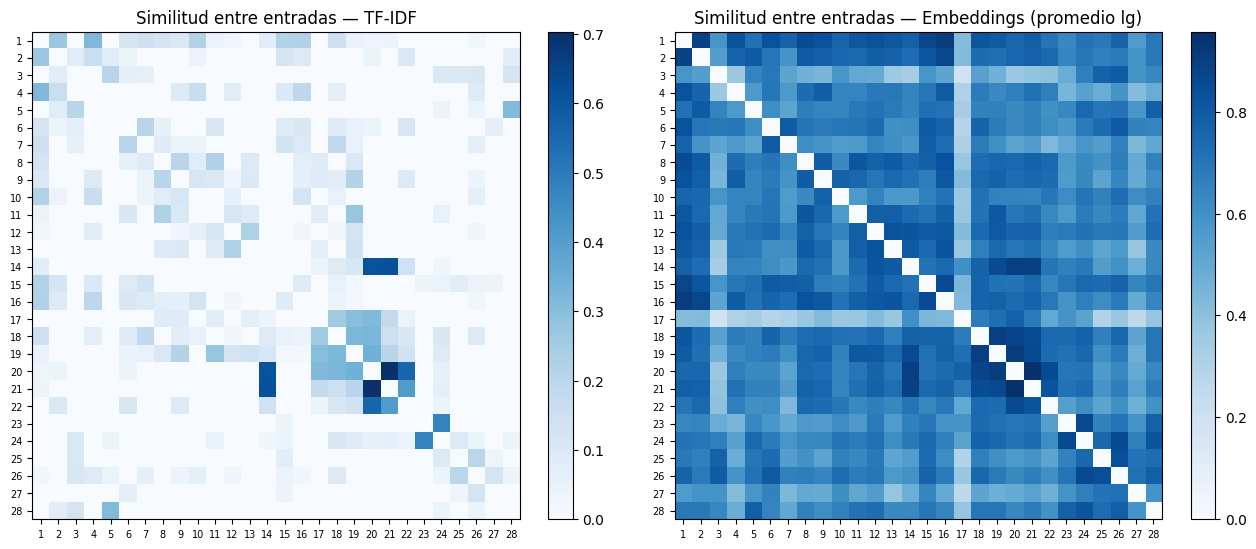

,similitud TF-IDF,entrada A,entrada B
0,0.70,20: ¿Qué incluye el Plan Anual?,21: ¿Cuál es el plan más conveniente?
1,0.62,14: ¿Tiene reportes contables o exportación a Excel?,21: ¿Cuál es el plan más conveniente?
2,0.61,14: ¿Tiene reportes contables o exportación a Excel?,20: ¿Qué incluye el Plan Anual?
3,0.56,20: ¿Qué incluye el Plan Anual?,22: ¿Tienen soporte técnico las 24 horas?
4,0.48,23: ¿Cómo pago la membresía?,24: ¿Cómo me registro?
5,0.41,21: ¿Cuál es el plan más conveniente?,22: ¿Tienen soporte técnico las 24 horas?
6,0.34,19: ¿Qué incluye el Plan Trimestral?,20: ¿Qué incluye el Plan Anual?
7,0.33,18: ¿Cuánto cuesta el Plan Mensual?,20: ¿Qué incluye el Plan Anual?


In [20]:
X_tfidf = bot_tfidf.matriz
E = np.array([con_peso._promedio(V) for V in con_peso.docs])          # vector promedio (lg) de cada entrada
E = E / np.linalg.norm(E, axis=1, keepdims=True)

S_tfidf = cosine_similarity(X_tfidf); np.fill_diagonal(S_tfidf, 0)
S_emb = cosine_similarity(E); np.fill_diagonal(S_emb, 0)

fig, ax = plt.subplots(1, 2, figsize=(13, 5.5))
for a, S, titulo in [(ax[0], S_tfidf, "TF-IDF"), (ax[1], S_emb, "Embeddings (promedio lg)")]:
    im = a.imshow(S, cmap="Blues")
    a.set_xticks(range(28)); a.set_xticklabels(df_faq.id, fontsize=7)
    a.set_yticks(range(28)); a.set_yticklabels(df_faq.id, fontsize=7)
    a.set_title(f"Similitud entre entradas — {titulo}")
    plt.colorbar(im, ax=a, fraction=0.046)
plt.tight_layout(); plt.show()

pares = sorted(((S_tfidf[i, j], FAQ[i][0], FAQ[j][0]) for i in range(28) for j in range(i + 1, 28)), reverse=True)[:8]
pd.DataFrame([(round(s, 2), f"{a}: {FAQ[a-1][2]}", f"{b}: {FAQ[b-1][2]}") for s, a, b in pares],
             columns=["similitud TF-IDF", "entrada A", "entrada B"])

Los pares más parecidos son los de **Planes** (Anual, el más conveniente, Excel, soporte 24/7): varias respuestas repiten "Plan Anual", "soporte prioritario 24/7", "reportes contables y exportación a Excel". También **pago ↔ registro** (las dos dicen "Mercado Pago").

En la matriz de **embeddings casi todo es "parecido"** (la mayoría de los pares está entre 0,6 y 0,9): al promediar, todas las respuestas quedan cerca del "centro" del vocabulario de negocios. La excepción es la entrada 17, que es casi toda precios y números (sin vector). Los embeddings separan mucho peor las entradas que TF-IDF, y eso anticipa por qué les cuesta decir "no sé".

### 5.2 Visualización en 2D con PCA y t-SNE (Unidad 8)

Proyecto las 28 entradas a dos dimensiones, coloreadas por categoría. Si las categorías forman grupos separados, la base está bien estructurada; si se mezclan, esas entradas van a confundirse. Para t-SNE uso `perplexity=8`, porque con solo 28 puntos el valor por defecto (30) no es válido.

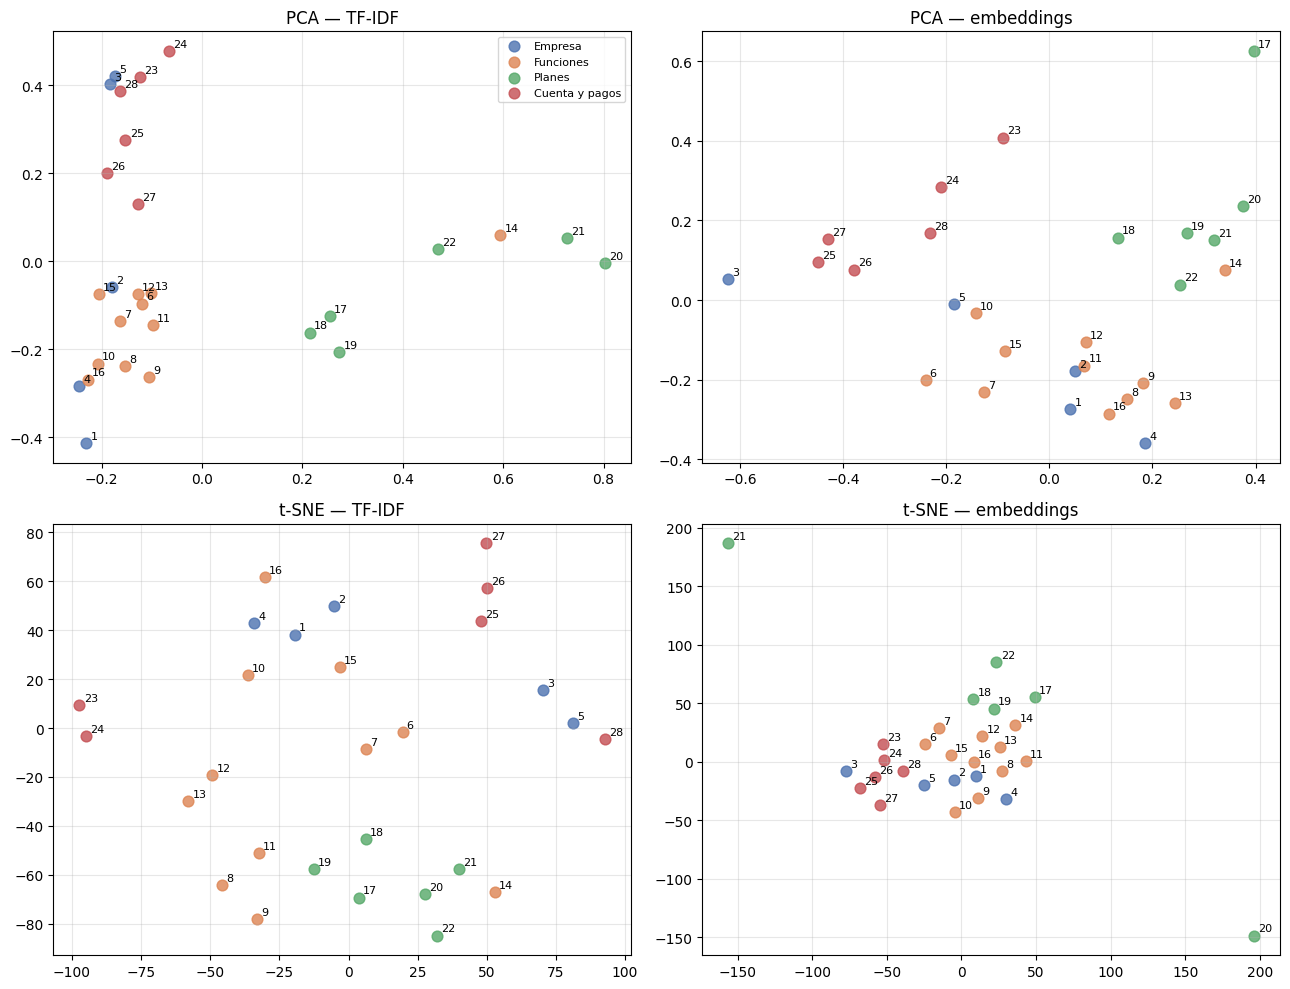

Varianza explicada por 2 componentes: TF-IDF 16% | embeddings 38%


In [21]:
colores = {"Empresa": "#4C72B0", "Funciones": "#DD8452", "Planes": "#55A868", "Cuenta y pagos": "#C44E52"}
proyecciones = {
    "PCA — TF-IDF": PCA(n_components=2, random_state=0).fit_transform(X_tfidf.toarray()),
    "PCA — embeddings": PCA(n_components=2, random_state=0).fit_transform(E),
    "t-SNE — TF-IDF": TSNE(n_components=2, perplexity=8, metric="cosine", init="random", random_state=0).fit_transform(X_tfidf.toarray()),
    "t-SNE — embeddings": TSNE(n_components=2, perplexity=8, metric="cosine", init="random", random_state=0).fit_transform(E),
}
fig, axs = plt.subplots(2, 2, figsize=(13, 10))
for a, (titulo, P2) in zip(axs.ravel(), proyecciones.items()):
    for cat, col in colores.items():
        m = (df_faq.categoria == cat).values
        a.scatter(P2[m, 0], P2[m, 1], c=col, label=cat, s=60, alpha=.8)
    for i, idf_ in enumerate(df_faq.id):
        a.annotate(str(idf_), (P2[i, 0], P2[i, 1]), fontsize=8, xytext=(3, 3), textcoords="offset points")
    a.set_title(titulo); a.grid(alpha=.3)
axs[0, 0].legend(fontsize=8)
plt.tight_layout(); plt.show()

pca_t = PCA(n_components=2).fit(X_tfidf.toarray()); pca_e = PCA(n_components=2).fit(E)
print(f"Varianza explicada por 2 componentes: TF-IDF {pca_t.explained_variance_ratio_.sum():.0%} | embeddings {pca_e.explained_variance_ratio_.sum():.0%}")

- **PCA sobre TF-IDF**: aunque dos componentes explican solo el 16% de la varianza (el espacio tiene casi 200 dimensiones y cada entrada usa palabras propias), el primer componente separa claramente **Planes** (17 a 22) del resto, y el segundo separa **Cuenta y pagos** junto con las entradas que derivan al teléfono (3, 5, 28).
- **t-SNE sobre TF-IDF**, que preserva vecindarios locales, muestra los mismos grupos con más detalle: Planes abajo (con la **14 de Excel adentro**, aunque yo la puse en Funciones), 23-24 (pago y registro) juntas, 25-27 (datos de acceso) juntas, y 3-5-28 (las que dan el teléfono) juntas aunque son de categorías distintas.
- **Con embeddings**, PCA ordena las categorías de forma parecida, pero t-SNE muestra una sola nube con dos puntos alejados (20 y 21): no hay grupos claros. Confirma lo de la matriz de similitud.
- No uso UMAP porque con 28 puntos no aporta nada distinto a t-SNE y requiere instalar `umap-learn`.

### 5.3 K-means: ¿qué grupos encuentra un algoritmo sin etiquetas?

Aplico K-means (como en *AA1 - Clustering K-means*) y elijo k con el **silhouette score**, usando distancia coseno.

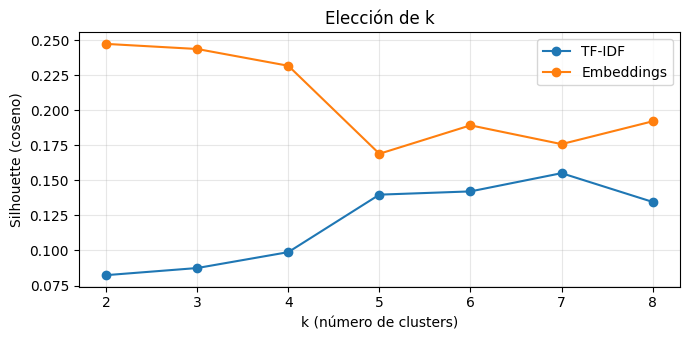

TF-IDF: mejor k = 7 (silhouette 0.16)
  cluster 0: 6. ¿Cómo funcionan los códigos QR? | 7. ¿Cuántos códigos QR puedo generar? | 8. ¿Qué es la ficha técnica del equipo?
  cluster 1: 14. ¿Tiene reportes contables o exportación a Excel? | 20. ¿Qué incluye el Plan Anual? | 21. ¿Cuál es el plan más conveniente? | 22. ¿Tienen soporte técnico las 24 horas?
  cluster 2: 1. ¿Qué es GPS Autoelevadores? | 2. ¿Qué servicios ofrecen? | 4. ¿Quién desarrolló el sistema? | 10. ¿El sistema avisa cuándo hay que hacer el service? | 15. ¿Puedo gestionar varios autoelevadores con una sola cuenta? | 16. ¿Para quién está pensado el sistema?
  cluster 3: 25. ¿Qué datos piden para registrarse? | 26. ¿Cómo ingreso al sistema? | 27. ¿Cómo accede el dueño o administrador?
  cluster 4: 23. ¿Cómo pago la membresía? | 24. ¿Cómo me registro?
  cluster 5: 3. ¿Cuál es el teléfono de contacto? | 5. ¿Dónde están ubicados y en qué horario atienden? | 28. ¿Hay prueba gratis o se puede cancelar en cualquier momento?
  clust

In [22]:
def kmeans_silhouette(M, ks=range(2, 9)):
    res = []
    for k in ks:
        km = KMeans(n_clusters=k, n_init=10, random_state=0).fit(M)
        res.append((k, silhouette_score(M, km.labels_, metric="cosine")))
    return pd.DataFrame(res, columns=["k", "silhouette"])

sil_t = kmeans_silhouette(X_tfidf.toarray()); sil_e = kmeans_silhouette(E)
plt.figure(figsize=(7, 3.5))
plt.plot(sil_t.k, sil_t.silhouette, "o-", label="TF-IDF"); plt.plot(sil_e.k, sil_e.silhouette, "o-", label="Embeddings")
plt.xlabel("k (número de clusters)"); plt.ylabel("Silhouette (coseno)"); plt.title("Elección de k"); plt.legend(); plt.grid(alpha=.3)
plt.tight_layout(); plt.show()

k_t = int(sil_t.loc[sil_t.silhouette.idxmax(), "k"])
km_t = KMeans(n_clusters=k_t, n_init=10, random_state=0).fit(X_tfidf.toarray())
print(f"TF-IDF: mejor k = {k_t} (silhouette {sil_t.silhouette.max():.2f})")
for c in range(k_t):
    print(f"  cluster {c}: " + " | ".join(f"{FAQ[i][0]}. {FAQ[i][2]}" for i in range(28) if km_t.labels_[i] == c))

k_e = int(sil_e.loc[sil_e.silhouette.idxmax(), "k"])
km_e = KMeans(n_clusters=k_e, n_init=10, random_state=0).fit(E)
print(f"\nEmbeddings: mejor k = {k_e} (silhouette {sil_e.silhouette.max():.2f})")
for c in range(k_e):
    print(f"  cluster {c}: ids {[FAQ[i][0] for i in range(28) if km_e.labels_[i] == c]}")

- Los **silhouette son bajos** en los dos casos (lejos de 1): las entradas **no forman grupos bien separados**. Es esperable en una base de preguntas frecuentes, donde todo habla del mismo producto.
- K-means sobre TF-IDF agrupa **por vocabulario compartido**, no por las categorías que yo definí: junta QR + ficha técnica, Plan Anual + Excel + soporte 24/7, pago + registro, y las entradas que derivan al teléfono.
- Con embeddings el mejor k es chico y los clusters son grandes: los embeddings ven "todo parecido", lo mismo que mostró la matriz de similitud.
- **Conclusión práctica:** cada cluster es una zona de **posibles confusiones**. Las entradas que caen juntas necesitan respuestas más diferenciadas o formulaciones alternativas (sección 7).

### 5.4 Modelado de tópicos con NMF

Como en el caso de estudio de Casciari (que termina con modelado de tópicos) y en el notebook de *Topic Modeling*, aplico **NMF** sobre la matriz TF-IDF para ver qué "temas" descubre sin etiquetas, y los comparo con mis 4 categorías. Uso NMF y no LDA porque con 28 documentos cortos LDA es muy inestable.

In [23]:
nmf = NMF(n_components=4, random_state=0, init="nndsvda", max_iter=2000).fit(X_tfidf)
vocab = bot_tfidf.vectorizer.get_feature_names_out()
for t, comp in enumerate(nmf.components_):
    print(f"Tópico {t}: {', '.join(vocab[i] for i in comp.argsort()[::-1][:8])}")

topico = nmf.transform(X_tfidf).argmax(axis=1)
pd.crosstab(pd.Series(topico, name="tópico NMF"), df_faq.categoria)

Tópico 0: plan, incluye, anual, soporte, exportacion, excel, contables, reportes
Tópico 1: autoelevadores, sistema, gps, qr, codigos, mantenimiento, service, equipo
Tópico 2: planes, fotos, incluyen, intervenciones, horometro, tecnicas, pdf, protocolos
Tópico 3: pago, sitio, telefono, 418301, 3498, contacto, mercado, web


categoria,Cuenta y pagos,Empresa,Funciones,Planes
tópico NMF,,,,
0,0,0,1,4
1,0,3,5,0
2,0,0,5,2
3,6,2,0,0


NMF recupera **casi las mismas categorías** que definí a mano: un tópico de **planes y Plan Anual**, uno del **sistema y el QR**, uno de **funciones incluidas en todos los planes** (horómetro, fotos, protocolos) y uno de **pago y contacto**, donde el número de teléfono 3498-418301 aparece como término central porque está en cuatro respuestas. Eso confirma que la base tiene una estructura razonable, y también que **el teléfono repetido acerca entradas que no tienen nada que ver** entre sí.

## 6. Evaluación y ambos chatbots funcionando (consigna 4)

### 6.1 Línea de base: búsqueda por palabras clave

Para tener una referencia, implemento el primer enfoque del notebook *Chatbot-retrieval*: un diccionario de palabras clave → respuesta, que devuelve la primera coincidencia.

In [24]:
PALABRAS_CLAVE = {
    "precio": 17, "precios": 17, "cuesta": 17, "cuestan": 17, "mensual": 18, "trimestral": 19, "anual": 20,
    "telefono": 3, "contacto": 3, "pago": 23, "pagar": 23, "registro": 24, "registrarse": 24, "qr": 6,
    "horometro": 9, "service": 10, "fotos": 11, "certificado": 12, "protocolos": 13, "excel": 14,
    "soporte": 22, "repuestos": 2, "mantenimiento": 2, "ingresar": 26, "contrasena": 26,
    "administrador": 27, "gratis": 28, "cancelar": 28, "ficha": 8, "desarrollo": 4, "horario": 5, "direccion": 5,
}

class ChatbotPalabrasClave:
    umbral = 0
    def responder(self, consulta):
        for w in palabras(consulta):           # devuelve la primera coincidencia, como en clase
            if w in PALABRAS_CLAVE:
                i = PALABRAS_CLAVE[w]
                return i, 1.0, FAQ[i - 1][3]
        return None, 0.0, MENSAJE_NO_ENTIENDO

bot_kw = ChatbotPalabrasClave()
resumen(evaluar(bot_kw))

{'exactitud': '47%',
 'parafrasis': '12/17',
 'sinonimos': '1/20',
 'ambigua': '3/3',
 'fuera': '5/5'}

### 6.2 Umbral de confianza

Cada chatbot devuelve la similitud de la mejor coincidencia. Si está por debajo del **umbral**, responde "no tengo una respuesta" y deriva al teléfono. Pruebo umbrales de 0 a 1 y mido la exactitud: una consulta del dominio es correcta si el id es el correcto **y** supera el umbral; una consulta `fuera` es correcta si **no** lo supera.

La exactitud máxima suele alcanzarse en un **rango** de umbrales (una "meseta"). En lugar de quedarme con el primer valor del rango, elijo el **centro de la meseta**, que es el más alejado de los bordes y el más robusto ante consultas nuevas.

> **Limitación:** elijo el umbral con el mismo set de prueba con el que evalúo, así que los resultados son algo optimistas. Con más datos usaría un conjunto de validación separado.

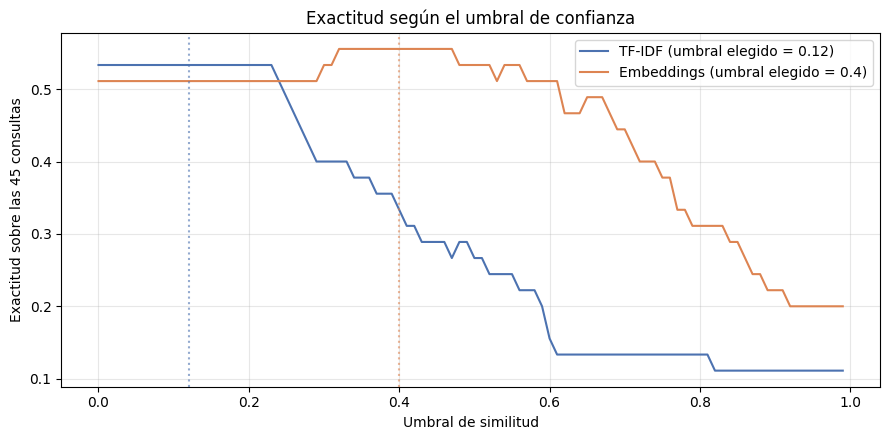

TF-IDF     : máxima exactitud 53% entre 0.0 y 0.23 -> umbral 0.12
Embeddings : máxima exactitud 56% entre 0.32 y 0.47 -> umbral 0.4

Similitud de las consultas fuera de la base (embeddings): [['alquilan autoelevadores?', 0.644], ['venden autoelevadores usados', 0.646], ['cuál es la capital de francia', 0.531], ['me recomendás una receta de pizza', 0.298], ['quién ganó el mundial 2022', 0.317]]


In [25]:
curva_tfidf = barrido_umbral(bot_tfidf)
curva_emb = barrido_umbral(bot_emb)
u_tfidf, ini_t, fin_t = umbral_robusto(curva_tfidf)
u_emb, ini_e, fin_e = umbral_robusto(curva_emb)
bot_tfidf.umbral, bot_emb.umbral = u_tfidf, u_emb

plt.figure(figsize=(9, 4.5))
plt.plot(curva_tfidf.umbral, curva_tfidf.exactitud, label=f"TF-IDF (umbral elegido = {u_tfidf})", color="#4C72B0")
plt.plot(curva_emb.umbral, curva_emb.exactitud, label=f"Embeddings (umbral elegido = {u_emb})", color="#DD8452")
plt.axvline(u_tfidf, color="#4C72B0", ls=":", alpha=.6); plt.axvline(u_emb, color="#DD8452", ls=":", alpha=.6)
plt.xlabel("Umbral de similitud"); plt.ylabel("Exactitud sobre las 45 consultas")
plt.title("Exactitud según el umbral de confianza"); plt.legend(); plt.grid(alpha=.3)
plt.tight_layout(); plt.show()

print(f"TF-IDF     : máxima exactitud {curva_tfidf.exactitud.max():.0%} entre {ini_t} y {fin_t} -> umbral {u_tfidf}")
print(f"Embeddings : máxima exactitud {curva_emb.exactitud.max():.0%} entre {ini_e} y {fin_e} -> umbral {u_emb}")

res_emb_sin = evaluar(ChatbotEmbeddings(FAQ, PREG_RESP, nlp_lg, preguntas=SOLO_PREGUNTA, peso_pregunta=0.5))
print("\nSimilitud de las consultas fuera de la base (embeddings):",
      res_emb_sin[res_emb_sin.tipo == "fuera"][["consulta", "similitud"]].values.tolist())

### 6.3 Ambos chatbots funcionando
***PROMPT UTILIZADO TANTO EN CLAUDE COMO EN GPT: "QUIERO UN SCRIPT PARA PODER INTRODUCIRLO EN EL SISTEMA DE MI CLIENTE, QUIERO QUE RESULTE INTERACTIVO Y SIMPATICO SIN PERDER LA SERIEDAD DE LA EMPRESA QUE SIMULE LA CONVERSACION CON UN POTENCIAL CLIENTE UTILIZANDO LO VISTO EN EL PROYECTO, TF-UDF Y EMBEDDINGS"***

Una conversación de ejemplo con los dos chatbots ya configurados:

In [26]:
def conversar(consultas, bots):
    for c in consultas:
        print(f"🧑 Usuario: {c}")
        for nombre, bot in bots:
            id_r, score, resp = bot.responder(c)
            etiqueta = f"id {id_r}" if id_r else "sin respuesta"
            print(f"   🤖 {nombre:12s} ({etiqueta}, sim={score:.2f}): {resp[:150]}{'...' if len(resp) > 150 else ''}")
        print()

BOTS = [("TF-IDF", bot_tfidf), ("Embeddings", bot_emb)]
conversar([
    "hola, cuánto sale el sistema?",
    "se puede abonar con tarjeta?",
    "me avisa cuando le toca el service al equipo?",
    "el operario puede ver el historial de la máquina desde el teléfono?",
    "cómo creo una cuenta",
    "alquilan autoelevadores?",
], BOTS)

🧑 Usuario: hola, cuánto sale el sistema?
   🤖 TF-IDF       (id 18, sim=0.26): El Plan Mensual cuesta $15.000 y se factura cada 30 días. Es la opción más flexible e incluye acceso completo al sistema, códigos QR ilimitados y aler...
   🤖 Embeddings   (id 10, sim=0.54): Sí. El sistema envía avisos antes de que venza el service programado de cada equipo, para que no se pase ningún mantenimiento.

🧑 Usuario: se puede abonar con tarjeta?
   🤖 TF-IDF       (sin respuesta, sim=0.00): Perdón, no tengo una respuesta para eso. Probá reformular la pregunta o comunicate al 3498-418301.
   🤖 Embeddings   (id 23, sim=0.53): El pago se hace con Mercado Pago, en una suscripción segura que acepta todos los medios de pago disponibles en Argentina.

🧑 Usuario: me avisa cuando le toca el service al equipo?
   🤖 TF-IDF       (id 10, sim=0.59): Sí. El sistema envía avisos antes de que venza el service programado de cada equipo, para que no se pase ningún mantenimiento.
   🤖 Embeddings   (id 10, sim=0.75): S

Para chatear en vivo en Colab, cambiar `MODO_INTERACTIVO = True` y ejecutar la celda. Escribir `salir` para terminar.

In [52]:
MODO_INTERACTIVO = False   # True para conversar en Colab

def chat_interactivo(bot, nombre):
    print(f"Asistente GPS Autoelevadores ({nombre}). Escribí 'salir' para terminar.")
    while True:
        entrada = input("Tú: ")
        if entrada.strip().lower() == "salir":
            print("Asistente: ¡Gracias por tu consulta! Ante cualquier duda llamanos al 3498-418301.")
            break
        _, score, resp = bot.responder(entrada)
        print(f"Asistente (sim={score:.2f}): {resp}\n")

if MODO_INTERACTIVO:
    chat_interactivo(bot_tfidf, "TF-IDF")   # o bot_emb

Asistente GPS Autoelevadores (TF-IDF). Escribí 'salir' para terminar.
Tú: costo mensual del servicio
Asistente (sim=0.36): GPS Autoelevadores trabaja en mantenimiento, refrigeración, repuestos y servicio técnico de autoelevadores. Para consultar o coordinar un servicio, llamá al 3498-418301.

Tú: hacen mantenimiento
Asistente (sim=0.22): Sí. El sistema envía avisos antes de que venza el service programado de cada equipo, para que no se pase ningún mantenimiento.



KeyboardInterrupt: Interrupted by user

### 6.4 Resultados consulta por consulta

Para cada una de las 45 consultas: qué entrada eligió cada chatbot, con qué similitud y si acertó (✅ / ❌). La tabla se guarda en `resultados_prueba_chatbots.csv`.

In [28]:
res_kw, res_tfidf, res_emb = evaluar(bot_kw), evaluar(bot_tfidf), evaluar(bot_emb)

def celda(ok, pred, sim):
    return f"{'✅' if ok else '❌'} {'no sabe' if pd.isna(pred) else int(pred)} ({sim:.2f})"

comparativa = pd.DataFrame({
    "consulta": res_tfidf.consulta, "tipo": res_tfidf.tipo,
    "esperado": res_tfidf.esperado.map(lambda e: "—" if e is None else e),
    "Palabras clave": [("✅ " if o else "❌ ") + ("no sabe" if pd.isna(p) else str(int(p))) for o, p in zip(res_kw.correcta, res_kw.predicho)],
    "TF-IDF": [celda(o, p, s) for o, p, s in zip(res_tfidf.correcta, res_tfidf.predicho, res_tfidf.similitud)],
    "Embeddings": [celda(o, p, s) for o, p, s in zip(res_emb.correcta, res_emb.predicho, res_emb.similitud)],
})
comparativa.to_csv("resultados_prueba_chatbots.csv", index=False, encoding="utf-8")
comparativa

,consulta,tipo,esperado,Palabras clave,TF-IDF,Embeddings
0,qué es gps autoelevadores,parafrasis,1,❌ no sabe,✅ 1 (0.59),✅ 1 (1.00)
1,para qué sirve este sistema,sinonimos,1,❌ no sabe,❌ 4 (0.47),❌ 9 (0.66)
2,hacen mantenimiento de autoelevadores?,parafrasis,2,✅ 2,❌ 1 (0.45),❌ 1 (0.90)
3,me pueden arreglar el equipo de frío,sinonimos,2,❌ no sabe,❌ 8 (0.42),❌ no sabe (0.39)
4,venden repuestos?,parafrasis,2,✅ 2,✅ 2 (0.24),✅ 2 (0.70)
5,cuál es el teléfono,parafrasis,3,✅ 3,✅ 3 (0.52),✅ 3 (1.00)
6,a qué número llamo para hacer una consulta,sinonimos,3,❌ no sabe,❌ 5 (0.26),❌ no sabe (0.39)
7,quién hizo la página,sinonimos,4,❌ no sabe,✅ 4 (0.35),❌ 3 (0.56)
8,dónde queda el taller,sinonimos,5,❌ no sabe,❌ 11 (0.17),❌ no sabe (0.37)
9,a qué hora abren,sinonimos,5,❌ no sabe,❌ no sabe (0.00),✅ 5 (0.47)


In [29]:
final = pd.DataFrame({"Palabras clave (base)": resumen(res_kw), "TF-IDF": resumen(res_tfidf),
                      "Embeddings (spaCy lg)": resumen(res_emb)}).T
print("Ambos aciertan :", int((res_tfidf.correcta & res_emb.correcta).sum()))
print("Solo TF-IDF    :", int((res_tfidf.correcta & ~res_emb.correcta).sum()))
print("Solo embeddings:", int((~res_tfidf.correcta & res_emb.correcta).sum()))
print("Ninguno        :", int((~res_tfidf.correcta & ~res_emb.correcta).sum()))
final

Ambos aciertan : 17
Solo TF-IDF    : 7
Solo embeddings: 8
Ninguno        : 13


,exactitud,parafrasis,sinonimos,ambigua,fuera
Palabras clave (base),47%,12/17,1/20,3/3,5/5
TF-IDF,53%,14/17,6/20,2/3,2/5
Embeddings (spaCy lg),56%,14/17,6/20,3/3,2/5


### 6.5 ¿Qué preguntas confunden?

Para cada error muestro **qué pregunta de la base eligió** el chatbot en lugar de la correcta, y si las dos entradas caen en el **mismo cluster** de K-means (sección 5.3).

In [30]:
pregunta_de = dict(zip(df_faq.id, df_faq.pregunta))
cluster_de = dict(zip(df_faq.id, km_t.labels_))

def confusiones(res, nombre):
    e = res[~res.correcta].copy()
    e["chatbot"] = nombre
    e["eligió"] = e.predicho.map(lambda p: "(no respondió)" if pd.isna(p) else f"{int(p)}. {pregunta_de[int(p)]}")
    primera = [None if x is None else (x if isinstance(x, int) else x[0]) for x in e.esperado]
    e["correcta"] = ["(no debía responder)" if x is None else f"{x}. {pregunta_de[x]}" for x in primera]
    e["mismo cluster"] = [("sí" if cluster_de[int(p)] == cluster_de[x] else "no") if (x is not None and not pd.isna(p)) else "—"
                          for p, x in zip(e.predicho, primera)]
    return e[["chatbot", "consulta", "tipo", "eligió", "correcta", "similitud", "mismo cluster"]]

errores = pd.concat([confusiones(res_tfidf, "TF-IDF"), confusiones(res_emb, "Embeddings")], ignore_index=True)
errores

,chatbot,consulta,tipo,eligió,correcta,similitud,mismo cluster
0,TF-IDF,para qué sirve este sistema,sinonimos,4. ¿Quién desarrolló el sistema?,1. ¿Qué es GPS Autoelevadores?,0.469,sí
1,TF-IDF,hacen mantenimiento de autoelevadores?,parafrasis,1. ¿Qué es GPS Autoelevadores?,2. ¿Qué servicios ofrecen?,0.452,sí
2,TF-IDF,me pueden arreglar el equipo de frío,sinonimos,8. ¿Qué es la ficha técnica del equipo?,2. ¿Qué servicios ofrecen?,0.423,no
3,TF-IDF,a qué número llamo para hacer una consulta,sinonimos,5. ¿Dónde están ubicados y en qué horario atienden?,3. ¿Cuál es el teléfono de contacto?,0.259,sí
4,TF-IDF,dónde queda el taller,sinonimos,11. ¿Puedo registrar las intervenciones con fotos?,5. ¿Dónde están ubicados y en qué horario atienden?,0.170,no
5,TF-IDF,a qué hora abren,sinonimos,(no respondió),5. ¿Dónde están ubicados y en qué horario atienden?,0.000,—
6,TF-IDF,cómo funciona el qr,parafrasis,7. ¿Cuántos códigos QR puedo generar?,6. ¿Cómo funcionan los códigos QR?,0.369,sí
7,TF-IDF,el operario puede ver el historial de la máquina desde el teléfono?,sinonimos,3. ¿Cuál es el teléfono de contacto?,6. ¿Cómo funcionan los códigos QR?,0.294,no
8,TF-IDF,puedo cargar imágenes de los trabajos realizados,sinonimos,13. ¿Qué son los protocolos oficiales?,11. ¿Puedo registrar las intervenciones con fotos?,0.392,sí
9,TF-IDF,tiene informes para el contador,sinonimos,(no respondió),14. ¿Tiene reportes contables o exportación a Excel?,0.000,—


In [31]:
conf = errores[errores["mismo cluster"] != "—"]
print(f"Errores donde el chatbot eligió otra entrada: {len(conf)}; "
      f"de esos, {int((conf['mismo cluster'] == 'sí').sum())} son entre entradas del mismo cluster de K-means.")

Errores donde el chatbot eligió otra entrada: 28; de esos, 11 son entre entradas del mismo cluster de K-means.


## 7. Mejora: formulaciones alternativas y chatbot híbrido

### 7.1 Formulaciones alternativas por pregunta

Los errores de la sección 6 tienen un patrón común: el cliente usa **palabras distintas** a las de la base ("cuánto sale", "abonar", "informes para el contador"). Así se arman los chatbots de atención reales (los *intents* de Dialogflow o Rasa): cada respuesta se asocia a **varias formas de preguntar lo mismo**.

Agrego **1 a 3 formulaciones alternativas** por entrada. Cada una se indexa como un documento más que apunta a la misma respuesta.

> **Cuidado con la "trampa":** las variantes las escribí yo, igual que las consultas de prueba. Para no copiar las pruebas dentro de la base, verifico que **ninguna variante sea casi igual a una consulta de prueba** (superposición de palabras). Igual el resultado es optimista: en un sistema real las variantes deberían salir de consultas reales de clientes.

In [32]:
VARIANTES = {1: ['¿Para qué sirve GPS Autoelevadores?', '¿Qué hace el sistema?'],
    2: ['¿Reparan autoelevadores?', '¿Trabajan con sistemas de refrigeración?', '¿Tienen repuestos para autoelevadores?'],
    3: ['¿Tienen un número de contacto?', '¿Cómo me comunico con ustedes?'],
    4: ['¿Qué empresa programó el software?'],
    5: ['¿Cuál es la dirección?', '¿Qué horarios tienen?'],
    6: ['¿Qué pasa cuando escaneo el código con el celular?'],
    7: ['¿Puedo poner un QR en cada máquina?'],
    8: ['¿Qué información muestra la ficha de cada máquina?'],
    9: ['¿Lleva la cuenta de las horas trabajadas de cada equipo?'],
    10: ['¿Me recuerda los mantenimientos pendientes?', '¿Tiene alertas de vencimiento del service?'],
    11: ['¿Puedo subir imágenes de cada reparación?', '¿Queda guardado cada trabajo realizado?'],
    12: ['¿Puedo darle al cliente un comprobante firmado?'],
    13: ['¿Tiene planillas o protocolos de mantenimiento?'],
    14: ['¿Puedo sacar informes para contabilidad?', '¿Se puede descargar la información en una planilla?'],
    15: ['¿Cuántos equipos puedo cargar en mi cuenta?'],
    16: ['¿Lo puede usar un taller chico?', '¿Sirve para empresas con muchas máquinas?'],
    17: ['¿Cuál es el precio de la membresía?', '¿Qué tarifas tienen?'],
    18: ['¿Cuánto se paga por mes?'],
    19: ['¿Cuánto vale el plan de tres meses?'],
    20: ['¿Qué beneficios tiene el plan de un año?'],
    21: ['¿Qué plan me recomiendan?', '¿Cuál plan elige la mayoría?'],
    22: ['¿Atienden a cualquier hora?', '¿El soporte está disponible siempre?'],
    23: ['¿Puedo pagar con tarjeta de crédito o débito?', '¿Aceptan Mercado Pago?'],
    24: ['¿Cómo me doy de alta?', '¿Cómo contrato el sistema?'],
    25: ['¿Qué información tengo que completar en el formulario?'],
    26: ['¿Dónde inicio sesión?', '¿Cómo entro con mi correo?'],
    27: ['¿Qué es la clave de Super Usuario?'],
    28: ['¿Tiene período de prueba?', '¿Cómo doy de baja la suscripción?'],
}

print("Variantes agregadas:", sum(len(v) for v in VARIANTES.values()), "para", len(VARIANTES), "entradas")

# Control de "fuga": superposición de palabras (Jaccard) entre cada variante y cada consulta de prueba
solap = sorted(((len(set(palabras(v)) & set(palabras(q))) / len(set(palabras(v)) | set(palabras(q))), v, q)
                for vs in VARIANTES.values() for v in vs for q, _, _ in PRUEBAS), reverse=True)
print("\nLas 5 parejas variante/consulta más parecidas:")
for j, v, q in solap[:5]:
    print(f"  {j:.2f} | {v}  <->  {q}")

Variantes agregadas: 44 para 28 entradas

Las 5 parejas variante/consulta más parecidas:
  0.50 | ¿Para qué sirve GPS Autoelevadores?  <->  qué es gps autoelevadores
  0.44 | ¿Cuál es el precio de la membresía?  <->  cuál es la capital de francia
  0.43 | ¿Para qué sirve GPS Autoelevadores?  <->  para qué sirve este sistema
  0.43 | ¿Cuál es la dirección?  <->  cuál es la capital de francia
  0.38 | ¿Cuál es el precio de la membresía?  <->  cuál es el teléfono


In [33]:
respuesta_de = {f[0]: f for f in FAQ}
FAQ_EXT = list(FAQ) + [(i, respuesta_de[i][1], v, respuesta_de[i][3]) for i, vs in VARIANTES.items() for v in vs]
TEXTOS_EXT = PREG_RESP + [v for vs in VARIANTES.values() for v in vs]
PREGUNTAS_EXT = SOLO_PREGUNTA + [v for vs in VARIANTES.values() for v in vs]

bot_tfidf_v = ChatbotTFIDF(FAQ_EXT, TEXTOS_EXT, prep=preprocesar)
bot_tfidf_v_lema = ChatbotTFIDF(FAQ_EXT, TEXTOS_EXT, prep=partial(preprocesar, lematizar=True))
bot_emb_v = ChatbotEmbeddings(FAQ_EXT, TEXTOS_EXT, nlp_lg, preguntas=PREGUNTAS_EXT, peso_pregunta=0.5)
for b in (bot_tfidf_v, bot_tfidf_v_lema, bot_emb_v):
    ajustar_umbral(b)

res_tfidf_v, res_emb_v = evaluar(bot_tfidf_v), evaluar(bot_emb_v)
print("Umbrales -> TF-IDF + var.:", bot_tfidf_v.umbral, "| Embeddings + var.:", bot_emb_v.umbral)

Umbrales -> TF-IDF + var.: 0.14 | Embeddings + var.: 0.44


### 7.2 Chatbot híbrido

Los dos chatbots aciertan **cosas distintas**, así que pruebo combinarlos: primero responde TF-IDF (preciso con palabras exactas y bueno para rechazar lo ajeno); si TF-IDF no encuentra nada por encima de su umbral, pregunto a los embeddings.

In [34]:
class ChatbotHibrido:
    umbral = 0
    def __init__(self, primero, segundo):
        self.primero, self.segundo = primero, segundo
    def responder(self, consulta):
        id_r, score, resp = self.primero.responder(consulta)
        if id_r is not None:
            return id_r, score, resp
        return self.segundo.responder(consulta)

bot_hibrido = ChatbotHibrido(bot_tfidf, bot_emb)
bot_hibrido_v = ChatbotHibrido(bot_tfidf_v, bot_emb_v)
res_hib, res_hib_v = evaluar(bot_hibrido), evaluar(bot_hibrido_v)

mejora = pd.DataFrame({
    "Palabras clave": resumen(res_kw),
    "TF-IDF": resumen(res_tfidf),
    "Embeddings": resumen(res_emb),
    "Híbrido": resumen(res_hib),
    "TF-IDF + variantes": resumen(res_tfidf_v),
    "TF-IDF + variantes (con lema)": resumen(evaluar(bot_tfidf_v_lema)),
    "Embeddings + variantes": resumen(res_emb_v),
    "Híbrido + variantes": resumen(res_hib_v),
}).T
mejora

,exactitud,parafrasis,sinonimos,ambigua,fuera
Palabras clave,47%,12/17,1/20,3/3,5/5
TF-IDF,53%,14/17,6/20,2/3,2/5
Embeddings,56%,14/17,6/20,3/3,2/5
Híbrido,58%,14/17,9/20,2/3,1/5
TF-IDF + variantes,67%,15/17,10/20,3/3,2/5
TF-IDF + variantes (con lema),56%,13/17,8/20,2/3,2/5
Embeddings + variantes,58%,14/17,7/20,3/3,2/5
Híbrido + variantes,64%,15/17,10/20,3/3,1/5


In [35]:
def cambios(antes, despues, nombre):
    arregla = despues[~antes.correcta & despues.correcta].consulta.tolist()
    rompe = despues[antes.correcta & ~despues.correcta].consulta.tolist()
    print(f"{nombre}\n   arregla ({len(arregla)}): {arregla}\n   empeora ({len(rompe)}): {rompe}\n")

cambios(res_tfidf, res_tfidf_v, "TF-IDF -> TF-IDF + variantes")
cambios(res_emb, res_emb_v, "Embeddings -> Embeddings + variantes")
cambios(res_tfidf_v, res_hib_v, "TF-IDF + variantes -> Híbrido + variantes")

conversar(["hola, cuánto sale el sistema?", "se puede abonar con tarjeta?", "tiene informes para el contador",
           "alquilan autoelevadores?"],
          [("TF-IDF+var", bot_tfidf_v), ("Emb+var", bot_emb_v)])

TF-IDF -> TF-IDF + variantes
   arregla (9): ['para qué sirve este sistema', 'a qué número llamo para hacer una consulta', 'puedo cargar imágenes de los trabajos realizados', 'tiene informes para el contador', 'valor de la suscripción por un mes', 'cuánto cuesta el plan trimestral', 'qué trae la suscripción de un año', 'se puede abonar con tarjeta?', 'cuánto ahorro con el plan anual']
   empeora (3): ['genera un comprobante del trabajo con imágenes del antes y después', 'tengo diez máquinas, necesito una cuenta para cada una?', 'cuánto sale']

Embeddings -> Embeddings + variantes
   arregla (2): ['para qué sirve este sistema', 'a qué número llamo para hacer una consulta']
   empeora (1): ['a qué hora abren']

TF-IDF + variantes -> Híbrido + variantes
   arregla (0): []
   empeora (1): ['cuál es la capital de francia']

🧑 Usuario: hola, cuánto sale el sistema?
   🤖 TF-IDF+var   (id 1, sim=0.62): GPS Autoelevadores es un Sistema de Gestión Técnica para flotas de autoelevadores. Permite d

**Resultado de la mejora (sección 7):**

- **TF-IDF + variantes es la mejor configuración: 67%** (30 de 45). Arregla 9 consultas y empeora 3. Las variantes le agregan justo lo que le faltaba, **el vocabulario del cliente**: *"se puede abonar con tarjeta?"* pasa de similitud 0 a la respuesta correcta gracias a "¿Puedo pagar con **tarjeta** de crédito o débito?", y *"tiene informes para el contador"* gracias a "¿Puedo sacar **informes** para contabilidad?".
- Las 3 que empeora muestran un **riesgo nuevo**: las variantes cortas "se roban" consultas. *"cuánto sale"* ahora elige "¿**Cuánto** se paga por mes?" (Plan Mensual) en vez de la tabla de todos los planes, y *"tengo diez **máquinas**…"* elige "¿Sirve para empresas con muchas **máquinas**?".
- **Embeddings + variantes sube poco (56% → 58%)**: ya entendían parte de los sinónimos, así que las variantes les aportan menos.
- **El chatbot híbrido no supera a TF-IDF + variantes** (64% contra 67%): cuando TF-IDF no encuentra nada, los embeddings casi siempre responden *algo*, y eso agrega un error ("la capital de Francia") sin arreglar ninguna consulta. Sin variantes, el híbrido sí ayuda (53% → 58%), porque los embeddings rescatan sinónimos que TF-IDF no ve.

## 8. Conclusiones (consigna 5)

### 8.1 Resultado general

| | Palabras clave | TF-IDF | Embeddings (spaCy `lg`) | TF-IDF + variantes | Embeddings + variantes |
|---|---|---|---|---|---|
| **Exactitud (45 consultas)** | 47% | 53% | 56% | **67%** | 58% |
| Paráfrasis (17) | 12 | 14 | 14 | **15** | 14 |
| Sinónimos (20) | 1 | 6 | 6 | **10** | 7 |
| Ambiguas (3) | 3 | 2 | 3 | 3 | 3 |
| Fuera de la base rechazadas (5) | **5** | 2 | 2 | 2 | 2 |

Con la base original, los dos chatbots están **casi empatados** (53% y 56%), pero aciertan **cosas distintas**: ambos aciertan 17 consultas, solo TF-IDF 7, solo embeddings 8, y ninguno 13. La búsqueda por palabras clave de la clase rechaza todo lo que no conoce (5/5 fuera), pero solo entiende 1 de 20 consultas con sinónimos.

### 8.2 ¿En qué respuestas falla cada chatbot y por qué?

**TF-IDF falla cuando el cliente no usa las palabras de la base, o cuando comparte una palabra engañosa:**
- **Sin ninguna palabra en común** (similitud 0): *"se puede abonar con tarjeta?"*, *"tiene informes para el contador"*, *"a qué hora abren"*. TF-IDF solo compara palabras idénticas.
- **Una palabra compartida que lleva a la entrada equivocada**: *"el operario puede ver el historial de la máquina desde el **teléfono**?"* → responde el **número de teléfono** de la empresa; *"para qué sirve este **sistema**"* → "¿Quién desarrolló el **sistema**?"; *"cómo creo una **cuenta**"* → "¿Puedo gestionar varios autoelevadores con una sola **cuenta**?".
- **Coincidencia exacta con otra pregunta**: *"**cuánto cuesta** el plan trimestral"* → "¿**Cuánto cuesta** el Plan Mensual?".

**Los embeddings entienden más sinónimos, pero fallan por otros motivos:**
- **Aciertan donde TF-IDF no puede**: *"abonar con tarjeta"* → Mercado Pago, *"el operario… desde el teléfono"* → QR, *"puedo cargar imágenes de los trabajos"* → fotos, *"informes para el contador"* → reportes contables.
- **Una palabra genérica idéntica pesa más que el tema**: *"qué protocolos **incluye**"* → "¿Qué **incluye** el Plan Trimestral?" (0,85); *"cómo registro las **horas** de uso"* → "soporte las 24 **horas**"; *"hay **atención** todo el día"* → "horarios de **atención**".
- **Empates**: *"hacen mantenimiento de autoelevadores?"* tiene las dos palabras en tres entradas distintas. El peso a la pregunta desempata, pero hacia la equivocada.
- **Palabras sin vector o filtradas**: "horómetro" no existe para el modelo, y *"cómo creo una cuenta"* queda **vacía** porque "cómo", "creo", "una" y "cuenta" son stop words en la lista de spaCy.

**A los dos les cuesta decir "no sé" cuando la pregunta es del rubro**: *"¿alquilan autoelevadores?"* y *"¿venden autoelevadores usados?"* comparten "autoelevadores", la palabra central del negocio, y ningún umbral las separa de las preguntas legítimas. Además, los embeddings no rechazan *"la capital de Francia"* (0,53 con la entrada de exportación a Excel), y TF-IDF con stop words de dominio responde *"**quién** ganó el mundial"* con "¿**Quién** desarrolló el sistema?".

### 8.3 ¿Qué preguntas confunden?

El análisis no supervisado de la sección 5 explica buena parte de las confusiones: de los 28 errores en que un chatbot eligió otra entrada, **11 son entre entradas del mismo cluster de K-means**.

| Consulta | Se confunde con | Por qué (sección 5) |
|---|---|---|
| "cuánto cuesta el plan trimestral", "cuánto ahorro con el plan anual" | 17, 18, 19 y 20 entre sí | Zona de **Planes**: el par más parecido de toda la base (20-21: 0,70) y el grupo más compacto en t-SNE. |
| "hacen mantenimiento de autoelevadores?", "para qué sirve este sistema" | 1, 2, 4, 16 entre sí | Mismo cluster: todas describen el sistema con "autoelevadores", "mantenimiento", "sistema". |
| "a qué número llamo para hacer una consulta" | 3 (teléfono) → 5 (ubicación) | El teléfono está en 4 respuestas; NMF lo pone como término central de un tópico y t-SNE junta 3, 5 y 28. |
| "puedo cargar imágenes de los trabajos realizados" | 11 (fotos) → 13 (protocolos) | Mismo cluster: "trabajos realizados" está literal en la respuesta de protocolos. |
| "dónde pongo mi usuario y contraseña" | 26 (ingresar) → 25 (datos de registro) | Mismo cluster (25-27): las dos respuestas dicen "usuario" y "contraseña". |
| "alquilan / venden autoelevadores" | → 1 o 2 | Son del rubro, pero la base no tiene una entrada para eso. |

**Conclusión:** buena parte del error **no es del algoritmo sino de la base**. Cuando dos respuestas comparten vocabulario, el chatbot no tiene cómo distinguirlas.

### 8.4 Comparación de los chatbots

- **TF-IDF es preciso con las palabras exactas** (14-15 de 17 paráfrasis) y **rechaza bien lo totalmente ajeno** (similitud 0), pero no entiende sinónimos. Con **formulaciones alternativas** es el que más mejora y termina siendo **el mejor (67%)**. Además es simple, rápido y fácil de explicar: siempre se puede ver qué palabra produjo la coincidencia.
- **Los embeddings entienden sinónimos sin trabajo extra**, pero sus errores son **menos predecibles** (palabras genéricas, empates, forma gramatical, palabras sin vector) y **les cuesta decir "no sé"**: como muestra la matriz de similitud, para ellos casi todo se parece.
- **El preprocesamiento importa tanto como el modelo**: quitar stop words hizo posible el umbral; las stop words a medida agregaron sinónimos; y en embeddings, cambiar el promedio por la máxima similitud con peso a la pregunta subió 9 puntos (47% → 56%).
- **Para el chatbot real del sitio elegiría TF-IDF + variantes**, con umbral y un mensaje que derive al teléfono. Las variantes se pueden ir agregando con las consultas reales que lleguen.

### 8.5 Cómo lo mejoraría
1. **Agregar entradas para lo que hoy no se responde** pero es del rubro ("¿alquilan autoelevadores?", "¿venden equipos?"), aunque sea para derivar al teléfono. Ningún umbral las filtra.
2. **Diferenciar las respuestas que se pisan** (la zona de Planes y las que repiten el teléfono), usando la matriz de similitud y los clusters como guía.
3. **Registrar las consultas que el bot no supo responder** y convertirlas en variantes nuevas: el chatbot mejora con el uso.
4. **Separar un conjunto de validación** para elegir umbrales y configuraciones, porque acá elegí y evalué con el mismo set de 45 consultas (resultados optimistas).
5. Probar **embeddings de oraciones** multilingües (*sentence-transformers*), que no están entre las librerías pedidas pero representan la oración completa y no palabra por palabra.

### 8.6 Qué aprendí
- **La calidad del dataset pesa más que el algoritmo**: agregar formulaciones alternativas subió TF-IDF 14 puntos, más que cualquier cambio de modelo o de preprocesamiento.
- **Las herramientas "generales" hay que revisarlas para el dominio**: la lista de stop words de spaCy borraba "cuenta" y "cuánto", y el lematizador convertía "GPS" en "gp". Lo mismo que muestra el caso de Casciari con las stop words a medida.
- **Las técnicas no supervisadas sirven para diagnosticar un chatbot**: la matriz de similitud, PCA/t-SNE, K-means y NMF anticipan qué preguntas se van a confundir antes de probarlas.
- En atención al cliente, **decir "no sé" es tan importante como responder bien**: es mejor derivar al teléfono que contestar con un precio o una condición equivocada. Por eso la regla de diseño fue **no inventar nada que el sitio no publica**.

## Referencias

- GPS Autoelevadores — Sistema de Gestión Técnica (fuente del dataset), páginas consultadas el 08/10/2026: https://www.gpsautoelevadores.com/ · https://www.gpsautoelevadores.com/membresias/planes · https://www.gpsautoelevadores.com/auth/registro
- Material de la cátedra (A. L. Diedrichs): notebooks *Chatbot-retrieval*, *Intro_Embeddings*, *3_1 spaCy embeddings*, *3_2 Embeddings*, *AA1 - Clustering K-means*, *PH Unidad 8 - Reducción de dimensionalidad (PCA, t-SNE, UMAP)*, *Topic Modeling*; presentaciones *Embeddings parte 1* y *TF-IDF explicado*; apunte de la Unidad 1; temas de la clase del 14/09/2026. Repositorio: https://github.com/anadiedrichs/procesamientoDelHabla
- Bagnato, J. I. (2019). *NLP: Analizamos los cuentos de Hernán Casciari*. Aprende Machine Learning: https://www.aprendemachinelearning.com/ejercicio-nlp-cuentos-de-hernan-casciari-python-espanol/
- spaCy — modelos en español `es_core_news_md` y `es_core_news_lg`: https://spacy.io/models/es · API de `Token`, `Doc` y `Vectors`: https://spacy.io/api
- scikit-learn — `TfidfVectorizer`, `cosine_similarity`, `KMeans`, `silhouette_score`, `PCA`, `TSNE`, `NMF`: https://scikit-learn.org/stable/
- Beautiful Soup — documentación: https://www.crummy.com/software/BeautifulSoup/bs4/doc/
- Mikolov, T. et al. (2013). *Efficient Estimation of Word Representations in Vector Space*. arXiv:1301.3781.
- Pennington, J., Socher, R., Manning, C. (2014). *GloVe: Global Vectors for Word Representation*. EMNLP.
- Sidorov, G. et al. (2014). *Soft Similarity and Soft Cosine Measure: Similarity of Features in Vector Space Model*. Computación y Sistemas 18(3). (Idea de comparar palabra a palabra.)
- Zhang, T. et al. (2020). *BERTScore: Evaluating Text Generation with BERT*. ICLR. (Idea de la máxima similitud por token.)
- Jurafsky, D. y Martin, J. H. *Speech and Language Processing* (3.ª ed., borrador), cap. 6 "Vector Semantics and Embeddings" y cap. 15 "Chatbots & Dialogue Systems": https://web.stanford.edu/~jurafsky/slp3/
- Asistencia de IA: Claude (Anthropic), ChatGPT (Openai) y se le pidio a Gemini que le de un formato academico a esta presentación.